[![Open In Colab](https://colab.research.google.com/assets/colab-badge.svg)](https://colab.research.google.com/github/owlmt/QML/blob/main/01_Network_Intrusion_Detection/QML_NoisyIDSBenchmark_Cirillo2026.ipynb)

# Benchmarking QML for intrusion detection on noisy simulated quantum computers: Cirillo et al. 2026 step by step

**Paper.** Franco Cirillo, Christian Esposito, Jung Taek Seo, *Benchmarking quantum machine learning methods for intrusion detection on noisy quantum computers*, Quantum Machine Intelligence **8**, 27 (2026). DOI: [10.1007/s42484-026-00379-4](https://doi.org/10.1007/s42484-026-00379-4).

**What this notebook does.** It rebuilds the paper's benchmark of three quantum classifiers (Pegasos-QSVC, VQC and a hybrid quantum-classical neural network) on the two datasets for which the paper reports numbers, **ToN_IoT** (network traffic) and **NSL-KDD**, and runs them first on an ideal simulator and then on *noisy* simulators built from three IBM device snapshots (`FakeNairobiV2`, `FakeLagosV2`, `FakePerth`). Every step has a plain-language explanation, a classical baseline (SVM, XGBoost, random forest, neural network) is trained on exactly the same inputs, and the notebook finishes with a table that puts its own numbers next to the paper's and gives a verdict per claim.

**How to run.** Google Colab, CPU runtime, *Runtime > Run all*. `FAST_MODE = True` (default) is a class demo that runs in roughly 10 to 15 minutes; `FAST_MODE = False` is the larger run described in the configuration cell (several hours on a laptop CPU; its code path was smoke-tested with tiny budgets, the outputs saved in this notebook are those of the FAST run). No account or token is needed: both datasets are downloaded from public mirrors inside the notebook.

**What you get at the end.** Dataset plots, drawings of the circuits that are really executed, accuracy/F1 tables for ideal and noisy simulation, a re-drawn "F1 versus CNOT count" figure, timing comparisons, and an honest verdict on which claims of the paper this reproduction supports.

**Scope.** Only what the paper reports numbers for is reproduced: ToN_IoT and NSL-KDD; Pegasos-QSVC, VQC, HQNN; ideal and fake-backend noisy simulation. The paper's results on real IBM hardware do not exist (all its noisy numbers come from fake backends), so there is nothing hardware-related to check. The other datasets in the related-work table (CIC-IDS2017, UNSW-NB15, ...) are cited from other papers and are not part of this study.

## The paper in one page

**Problem.** Intrusion detection (is a network connection normal or an attack?) with quantum machine learning on *noisy* (NISQ) hardware. The authors do not claim quantum advantage; they want design rules for noise-resilient circuits.

**Decision.** Binary: normal (0) versus attack (1), attack is the positive class.

**Data.**
* **ToN_IoT** network file (`Train_Test_Network`, 211,043 rows, 44 columns, 10 classes: normal plus 9 attack types, Table 1).
* **NSL-KDD** (`KDDTrain+` 125,972 rows, 41 features, 5 families, Table 2).
* Preprocessing: clean, encode categoricals, stratified 80/20 split, then a *balanced 15 % sample per class* (ToN_IoT 11,270 train + 2,818 test; NSL-KDD 15,114 train + 3,780 test), normalise, **PCA with as many components as qubits** (2 to 10).

**Models.**
1. **Pegasos-QSVC**: a stochastic-gradient (Pegasos) support vector machine on a quantum fidelity kernel. Regularisation `C` 0.01 to 1000 (1000 chosen), 20 to 500 steps (100 chosen). Feature maps: `ZFeatureMap`, `ZZFeatureMap` (linear / full / circular entanglement), `PauliFeatureMap` with 10 Pauli strings (`X, Y, XX, XZ, ZX, YZ, ZY, Z+YY, Z+XX, Z+Y+ZZ`) = 14 maps, 1 to 3 repetitions, 2 to 10 qubits (378 configurations on ToN_IoT).
2. **VQC**: feature map plus ansatz (`RealAmplitudes`, `EfficientSU2`, `TwoLocal`, `PauliTwoDesign`), 1 to 3 repetitions, 2 to 8 qubits, optimisers COBYLA (50 or 200 iterations), SPSA, NFT, Nelder-Mead, Powell.
3. **HQNN**: Linear layer, ReLU, Linear layer, then a Qiskit `EstimatorQNN` (feature map + ansatz) connected to PyTorch with `TorchConnector`; Adam, learning rate 0.001, batch 64, 20 epochs.

**Noise.** `qiskit-aer` with the noise model of `FakeNairobiV2`, `FakeLagosV2` and `FakePerth` (7 qubits, same coupling map, different error levels; FakeLagos has a bad readout error and bad CNOTs), 1024 shots, 4 seeds (12345 to 12348), mean +- std reported.

**Claims that can be checked here.**
* Table 11: Pegasos-QSVC needs a large `C` (92.25 % accuracy at `C=1000`, collapsing to "everything is an attack", 74.56 %, for `C<=1`).
* Tables 12 and 13: best Pegasos-QSVC (7 qubits, `ZFeatureMap`, 2 reps): ToN_IoT / NSL-KDD accuracy 95.44 % / 95.80 % ideal, 93.24 % / 94.60 % (F1 94.13 % on NSL-KDD, the abstract's headline) under noise.
* Tables 15 and 16: VQC accuracies around 90 to 92 % ideal and 87 to 91 % noisy for 3-qubit circuits; some optimiser/circuit combinations collapse under noise (F1 down to about 19 to 45 %).
* Tables 17 and 18: HQNN 95.4 % / 97.1 % ideal, 94.86 % (Nairobi), 90.89 % (Lagos), 91.05 % (Perth) noisy.
* Table 19: classical SVM / XGBoost / random forest / neural network accuracy for 2 to 10 features (XGBoost up to 99.1 % on ToN_IoT).
* Qualitative claims: noise lowers accuracy; FakeLagos is the most noise-sensitive backend for CNOT-heavy circuits; F1 is best for a moderate number of CNOTs (Fig. 10); classical models still reach the highest peak accuracy.
* Timing (Figs. 6 to 9) is measured on a 56-core Xeon server and is **not** reproducible in absolute terms.

### What follows the paper and what had to be chosen

The paper leaves many details open (data cleaning, the exact feature scaling, hybrid network sizes, how noise was injected for training). Everything not stated is marked `# CHOICE:` in the code.

| Item | Paper | This notebook |
|---|---|---|
| ToN_IoT file | `Train_Test_Network`, 211,043 rows | same file from the public Hugging Face mirror `codymlewis/TON_IoT_network` (identical class counts to the paper's Table 1) |
| NSL-KDD file | `KDDTrain+` (125,972) / `KDDTest+` | `KDDTrain+` from a GitHub mirror; the paper's 15 % sample is taken from it, like the paper |
| Labels | normal vs attack | same (`label` column for ToN_IoT; `attack != normal` for NSL-KDD); the multi-class family is kept for the plots and for stratification |
| Cleaning | "cleaning and encoding categorical features" | drop IPs, ports and the text columns' identifiers; categorical columns become integer codes (`# CHOICE`); constant columns dropped; duplicates **kept** (the paper's row counts include them) |
| Sampling | 15 % balanced sample per class, then 80/20 | stratified sample of 14,088 (ToN_IoT) and 18,894 (NSL-KDD) rows by class family, then stratified 80/20 (the paper's sizes are matched to within 1 row) |
| Scaling + PCA | "normalised, PCA with n_qubits components" | signed log1p -> StandardScaler -> PCA(n_qubits) -> clip to the training 1st-99th percentile -> MinMaxScaler((0, a_max)), all fitted on the training split only; `a_max` (the kernel bandwidth) tuned on a validation split of the training data (`# CHOICE`). The log and the clipping were chosen on a validation split of the training data because without them a few extreme flows squeeze the whole cloud into a sliver of the angle range and even the classical RBF-SVM falls to 87 to 90 % (the paper's SVM reaches 96 %) |
| Pegasos-QSVC | `C=1000`, 100 steps | same; ideal kernel computed exactly from statevectors, noisy kernel from `P(0...0)` of the compute-uncompute circuit on a noisy Aer simulator with 1024 shots |
| Pauli feature-map entanglement | not stated | Qiskit default (`full`) |
| Pegasos prediction | Qiskit `PegasosQSVC` | same class, only the decision function is batched (checked equal to the original, see Section 5) |
| VQC | RealAmplitudes / EfficientSU2 etc., COBYLA 50 or 200 iterations, full training set | same circuits and optimisers, **much smaller** training budgets (see the configuration cell) |
| VQC noisy runs | trained on the noisy simulator | same: `VQC(sampler=AerSampler(noise_model), pass_manager=<preset for the fake backend>)` |
| HQNN hidden size, loss, output | not stated | Linear(q,8) - ReLU - Linear(8,q) - quantum layer returning `<Z...Z>`; target `2y-1`, MSE loss, class = sign (`# CHOICE`) |
| HQNN quantum layer | `EstimatorQNN` + `TorchConnector` (parameter-shift) | a batched Aer layer with finite-difference gradients, **checked equal** to `EstimatorQNN` forward and backward (Section 7); parameter-shift through the Estimator primitive takes about 30 s per 64-sample step here |
| HQNN noisy runs | not stated how trained | trained ideally, then **evaluated** on the noisy simulators (training under noise is too slow here) |
| HQNN hyper-parameters | Adam, lr 0.001, batch 64, 20 epochs, whole training set | Adam, lr 0.01, small batches and a few epochs on a subset (fewer steps, so a larger step size) |
| Seeds | 12345 to 12348, 4 runs | `SEEDS` in the configuration cell (1 seed in FAST_MODE, 2 in the full run for Pegasos-QSVC) |
| Classical baselines | SVM, XGBoost, random forest, neural network, 2 to 10 features, same inputs | `SVC(rbf)`, `XGBClassifier`, `RandomForestClassifier`, `MLPClassifier`, same PCA inputs |
| Hardware | none (fake backends only) | none |
| Timing | 56-core Xeon server | this machine; only relative comparisons are meaningful |

## 1. Setup

The first cell installs pinned, tested versions (it does nothing locally if they are already importable). On Colab a *session restart* may be requested after the install; if so, run all cells again.

In [1]:
import importlib.util, subprocess, sys
IN_COLAB = "google.colab" in sys.modules
def _have(m):
    return importlib.util.find_spec(m) is not None
if IN_COLAB or not all(_have(m) for m in ["qiskit", "qiskit_machine_learning", "qiskit_aer", "qiskit_ibm_runtime"]):
    subprocess.run([sys.executable, "-m", "pip", "-q", "install", "qiskit==2.5.2", "qiskit-machine-learning==0.9.1",
                    "qiskit-aer==0.17.2", "qiskit-ibm-runtime==0.50.0", "pylatexenc", "xgboost", "huggingface_hub"], check=False)
    print("installed pinned versions; if Colab asks for a restart, restart and run all cells again")
else:
    print("pinned libraries already importable; nothing to install")

pinned libraries already importable; nothing to install


### 1.1 Configuration

Every tunable constant is here. `FAST_MODE = True` is a demo with small budgets; `FAST_MODE = False` is the larger run (documented below; it needs several hours on a loaded laptop CPU, the noisy Pegasos runs alone take about half an hour, and it was only smoke-tested here). The paper's own budgets (378 Pegasos configurations, 200 VQC iterations on 11,270 training rows, HQNN with 20 epochs and training times of 10 to 80 hours on a 56-core server) are far beyond a notebook; the reduced budgets are listed in the "Paper vs this notebook" table above.

In [2]:
import math
FAST_MODE = True            # True: demo (about 10-15 min). False: larger run (several hours on a laptop CPU)
SEED = 42                   # global seed (data checks, torch init); per-run seeds come from SEEDS
DATA_DIR = "data"           # downloads are cached here
IBM_TOKEN = ""              # unused: the paper has no real-hardware numbers
SHOTS = 1024                # paper: all simulations use 1024 shots
TOL = 2.0                   # a numeric claim is "reproduced" when within 2 accuracy points (0.02 F1)
TEST_FRAC = 0.2             # paper: 80/20 split
N_TOTAL = {"ToN_IoT": 14088, "NSL-KDD": 18894}   # paper sample sizes: 11,270+2,818 and 15,114+3,780 (train+test)
AMAX_GRID = [math.pi / 2, math.pi, 2 * math.pi]  # CHOICE: candidate kernel bandwidths (angle range of the MinMax scaling)
BACKENDS_ALL = ["FakeNairobiV2", "FakeLagosV2", "FakePerth"]

if FAST_MODE:
    SEEDS = [12345]                                   # paper: 12345-12348
    CLASSICAL_Q = [3, 5, 7]                           # paper Table 19: 2..10 features
    C_SWEEP = [1000, 100, 10, 1]                      # paper Table 11: 1000 ... 0.01
    STEPS_SWEEP = [20, 100]                           # paper: 20, 50, 100, 200, 500
    QSVC_NOISELESS = ["Z7r2", "ZZlin6r1", "ZYY4r1"]   # paper Table 12 has 8 configurations
    QSVC_NOISY = ["Z7r2"]                             # paper Table 13 has 8 configurations
    NOISY_BACKENDS = ["FakeLagosV2", "FakePerth"]
    NOISY_STEPS, NOISY_N_TEST = 50, 30                # noisy kernel runs are about 1000x slower than the ideal ones
    VQC_CFGS = ["PY3"]                                # paper Tables 15/16 configurations
    VQC_NOISY_CFGS = ["PY3"]
    VQC_OPTIMIZERS = ["COBYLA"]
    VQC_TRAIN, VQC_TEST, VQC_ITERS = 80, 200, 20      # paper: 11,270 train rows, 50-200 iterations
    VQC_NOISY_BACKENDS, VQC_NOISY_TEST = ["FakeLagosV2", "FakePerth"], 60
    HQNN_CFGS = ["H3q"]
    HQNN_TRAIN, HQNN_TEST, HQNN_EPOCHS, HQNN_BATCH, HQNN_LR = 128, 300, 4, 16, 0.01
    HQNN_NOISY_BACKENDS, HQNN_NOISY_TEST = ["FakeLagosV2", "FakePerth"], 60
else:
    SEEDS = [12345, 12346]
    CLASSICAL_Q = list(range(2, 11))
    C_SWEEP = [1000, 100, 10, 1, 0.1, 0.01]
    STEPS_SWEEP = [20, 50, 100, 200, 500]
    QSVC_NOISELESS = ["ZZlin6r1", "PZX6r1", "ZYY4r1", "Z7r2", "PXX5r2", "PZXX6r2", "PZYZZ4r2", "ZZlin5r3"]
    QSVC_NOISY = ["Z7r2", "ZYY4r1"]
    NOISY_BACKENDS = BACKENDS_ALL
    NOISY_STEPS, NOISY_N_TEST = 100, 100
    VQC_CFGS = ["PY3", "ZZ3"]
    VQC_NOISY_CFGS = ["PY3"]                          # noisy VQC training is the most expensive part: only the paper's best noisy circuit
    VQC_OPTIMIZERS = ["COBYLA", "SPSA", "NELDER_MEAD", "POWELL"]
    VQC_TRAIN, VQC_TEST, VQC_ITERS = 150, 400, 50
    VQC_NOISY_BACKENDS, VQC_NOISY_TEST = BACKENDS_ALL, 150
    HQNN_CFGS = ["H3q", "H6q"]
    HQNN_TRAIN, HQNN_TEST, HQNN_EPOCHS, HQNN_BATCH, HQNN_LR = 192, 600, 4, 16, 0.01
    HQNN_NOISY_BACKENDS, HQNN_NOISY_TEST = BACKENDS_ALL, 100
print("FAST_MODE =", FAST_MODE, "| seeds:", SEEDS, "| noisy backends:", NOISY_BACKENDS)

FAST_MODE = True | seeds: [12345] | noisy backends: ['FakeLagosV2', 'FakePerth']


In [3]:
import os, time, shutil, zipfile, warnings
import numpy as np, pandas as pd
import matplotlib.pyplot as plt
import requests, torch
warnings.filterwarnings("ignore")
import qiskit, qiskit_aer, qiskit_machine_learning, qiskit_ibm_runtime
from qiskit import QuantumCircuit, transpile
from qiskit.circuit import Parameter
from qiskit.circuit.library import z_feature_map, zz_feature_map, pauli_feature_map, real_amplitudes, efficient_su2
from qiskit.quantum_info import SparsePauliOp, Statevector
from qiskit.primitives import StatevectorEstimator
from qiskit.transpiler import generate_preset_pass_manager
from qiskit_aer import AerSimulator
from qiskit_aer.noise import NoiseModel
from qiskit_aer.primitives import SamplerV2 as AerSampler
from qiskit_ibm_runtime.fake_provider import FakeLagosV2, FakeNairobiV2, FakePerth
from qiskit_machine_learning.algorithms import VQC, PegasosQSVC
from qiskit_machine_learning.kernels import BaseKernel, FidelityStatevectorKernel
from qiskit_machine_learning.optimizers import COBYLA, SPSA, NELDER_MEAD, POWELL
from qiskit_machine_learning.neural_networks import EstimatorQNN
from qiskit_machine_learning.connectors import TorchConnector
from qiskit_machine_learning.utils import algorithm_globals
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler, MinMaxScaler
from sklearn.decomposition import PCA
from sklearn.svm import SVC
from sklearn.ensemble import RandomForestClassifier
from sklearn.neural_network import MLPClassifier
from sklearn.metrics import accuracy_score, precision_score, recall_score, f1_score, confusion_matrix
from xgboost import XGBClassifier
from IPython.display import display

algorithm_globals.random_seed = SEED
rng = np.random.default_rng(SEED)
torch.manual_seed(SEED)
os.makedirs(DATA_DIR, exist_ok=True)
plt.rcParams.update({"figure.dpi": 80, "savefig.dpi": 80, "axes.grid": True, "grid.alpha": 0.3})
print("qiskit", qiskit.__version__, "| aer", qiskit_aer.__version__, "| qiskit-machine-learning", qiskit_machine_learning.__version__,
      "| ibm-runtime", qiskit_ibm_runtime.__version__, "| torch", torch.__version__)
FAKE = {"FakeNairobiV2": FakeNairobiV2(), "FakeLagosV2": FakeLagosV2(), "FakePerth": FakePerth()}
for k, b in FAKE.items():
    print(k, "qubits:", b.num_qubits, "| coupling edges:", len(b.coupling_map.get_edges()) // 2)

qiskit 2.5.2 | aer 0.17.2 | qiskit-machine-learning 0.9.1 | ibm-runtime 0.50.0 | torch 2.14.1+cpu
FakeNairobiV2 qubits: 7 | coupling edges: 6
FakeLagosV2 qubits: 7 | coupling edges: 6
FakePerth qubits: 7 | coupling edges: 6


### 1.2 Helper library: data, preprocessing, metrics

* `make_split` draws the paper-sized stratified sample and the 80/20 split; `prep` applies a signed `log1p` (byte and packet counts are heavy-tailed), StandardScaler, PCA, clips the PCA coordinates to their training 1st-99th percentile and rescales them to `[0, a_max]`, everything fitted on the training rows only (test angles are clipped to the training range).
* All metrics treat *attack* (label 1) as the positive class, as in the paper (Table 11's all-positive collapse has recall 100 %).

In [4]:
HF_TOKEN = os.environ.get("HF_TOKEN")
if HF_TOKEN is None:
    try:
        from google.colab import userdata          # Colab: Settings > Secrets > HF_TOKEN
        HF_TOKEN = userdata.get("HF_TOKEN")
    except Exception:
        HF_TOKEN = None
# Both Hugging Face datasets used below are public: the token is only passed on if the reader has one (no gated data here).

NSL_COLS = ["duration", "protocol_type", "service", "flag", "src_bytes", "dst_bytes", "land", "wrong_fragment", "urgent", "hot",
            "num_failed_logins", "logged_in", "num_compromised", "root_shell", "su_attempted", "num_root", "num_file_creations",
            "num_shells", "num_access_files", "num_outbound_cmds", "is_host_login", "is_guest_login", "count", "srv_count",
            "serror_rate", "srv_serror_rate", "rerror_rate", "srv_rerror_rate", "same_srv_rate", "diff_srv_rate",
            "srv_diff_host_rate", "dst_host_count", "dst_host_srv_count", "dst_host_same_srv_rate", "dst_host_diff_srv_rate",
            "dst_host_same_src_port_rate", "dst_host_srv_diff_host_rate", "dst_host_serror_rate", "dst_host_srv_serror_rate",
            "dst_host_rerror_rate", "dst_host_srv_rerror_rate", "attack", "difficulty"]
NSL_FAMILY = {"normal": "Normal"}
for fam, names in {"DoS": "back land neptune pod smurf teardrop apache2 udpstorm processtable worm mailbomb",
                   "Probe": "ipsweep nmap portsweep satan mscan saint",
                   "R2L": "ftp_write guess_passwd imap multihop phf spy warezclient warezmaster sendmail named snmpgetattack snmpguess xlock xsnoop httptunnel",
                   "U2R": "buffer_overflow loadmodule perl rootkit ps sqlattack xterm"}.items():
    NSL_FAMILY.update({n: fam for n in names.split()})
NSL_URLS = {"KDDTrain+.txt": ["https://raw.githubusercontent.com/defcom17/NSL_KDD/master/KDDTrain%2B.txt",
                              "https://raw.githubusercontent.com/jmnwong/NSL-KDD-Dataset/master/KDDTrain%2B.txt"]}

def download(urls, path):
    if os.path.exists(path) and os.path.getsize(path) > 0:
        return path
    for u in urls:
        try:
            r = requests.get(u, timeout=120); r.raise_for_status()
            open(path, "wb").write(r.content); return path
        except Exception as e:
            print("download failed:", u, repr(e)[:100])
    raise RuntimeError("no mirror worked for " + path)

def load_ton():
    path = os.path.join(DATA_DIR, "train_test_network.csv")
    if not os.path.exists(path):
        from huggingface_hub import hf_hub_download
        try:
            hf_hub_download("codymlewis/TON_IoT_network", "train_test_network.csv", repo_type="dataset", local_dir=DATA_DIR, token=HF_TOKEN)
        except Exception as e:
            print("primary mirror failed:", repr(e)[:120], "-> zip mirror")
            zp = hf_hub_download("m-hesam-moradian/ToN_IoT_Train_Test_datasets", "Train_Test_datasets.zip", repo_type="dataset",
                                 local_dir=DATA_DIR, token=HF_TOKEN)
            with zipfile.ZipFile(zp) as z:
                member = [n for n in z.namelist() if n.lower().endswith("train_test_network.csv")][0]
                with z.open(member) as src, open(path, "wb") as dst:
                    shutil.copyfileobj(src, dst)
            os.remove(zp)                                            # do not keep the 90 MB archive
    raw = pd.read_csv(path, low_memory=False)
    y = raw["label"].values.astype(int)
    fam = raw["type"].astype(str).values
    X = raw.drop(columns=["src_ip", "dst_ip", "src_port", "dst_port", "label", "type"]).copy()   # CHOICE: identifiers and ports dropped
    for c in X.columns:
        if not pd.api.types.is_numeric_dtype(X[c]):
            X[c] = X[c].astype("category").cat.codes                  # CHOICE: integer codes for text columns
    X = X.apply(pd.to_numeric, errors="coerce").replace([np.inf, -np.inf], np.nan).fillna(0)
    X = X.loc[:, X.nunique() > 1]
    return dict(raw=raw, X=X, y=y, fam=fam, label_col="type", binary_col="label")

def load_nsl():
    path = download(NSL_URLS["KDDTrain+.txt"], os.path.join(DATA_DIR, "KDDTrain+.txt"))
    raw = pd.read_csv(path, header=None, names=NSL_COLS)
    y = (raw["attack"] != "normal").astype(int).values
    fam = raw["attack"].map(NSL_FAMILY).fillna("Other").values
    X = raw.drop(columns=["attack", "difficulty"]).copy()
    for c in ["protocol_type", "service", "flag"]:
        X[c] = X[c].astype("category").cat.codes                      # CHOICE: integer codes
    X = X.loc[:, X.nunique() > 1]
    return dict(raw=raw, X=X, y=y, fam=fam, label_col="attack", binary_col=None)

def make_split(ds, seed):
    """Stratified sample of the paper's size, then stratified 80/20 split. Returns row positions into DATA[ds]."""
    fam = DATA[ds]["fam"]; idx = np.arange(len(fam))
    if N_TOTAL[ds] < len(idx):
        idx, _ = train_test_split(idx, train_size=N_TOTAL[ds], stratify=fam, random_state=seed)
    tr, te = train_test_split(idx, test_size=TEST_FRAC, stratify=fam[idx], random_state=seed)
    return tr, te

def take(idx, y, n, seed):
    """Stratified (by label) random subset of at most n rows of idx."""
    if n is None or n >= len(idx):
        return idx
    sub, _ = train_test_split(idx, train_size=n, stratify=y[idx], random_state=seed)
    return sub

def signed_log(a):
    return np.sign(a) * np.log1p(np.abs(a))

def pca_coords(ds, tr, te, q):
    """signed log1p -> StandardScaler -> PCA(q); fitted on the training rows only. Returns the raw PCA coordinates."""
    X = DATA[ds]["X"].values.astype(float)
    A, B = signed_log(X[tr]), signed_log(X[te])          # CHOICE: byte/packet counts are heavy-tailed, the log keeps outliers from dominating the PCA
    sc = StandardScaler().fit(A)
    pca = PCA(n_components=q, random_state=SEED).fit(sc.transform(A))
    return pca.transform(sc.transform(A)), pca.transform(sc.transform(B))

def prep(ds, tr, te, q, amax=math.pi):
    """signed log1p -> StandardScaler -> PCA(q) -> clip to the training 1st-99th percentile -> MinMax((0, amax)); fitted on the training rows only."""
    Ptr, Pte = pca_coords(ds, tr, te, q)
    lo, hi = np.percentile(Ptr, [1, 99], axis=0)           # CHOICE: tails clipped so that a few extreme flows do not squeeze everybody else into a tiny angle range
    Ptr, Pte = np.clip(Ptr, lo, hi), np.clip(Pte, lo, hi)
    mm = MinMaxScaler((0, amax)).fit(Ptr)
    return np.clip(mm.transform(Ptr), 0, amax), np.clip(mm.transform(Pte), 0, amax)

def metrics(y_true, y_pred):
    return dict(acc=100 * accuracy_score(y_true, y_pred),
                prec=100 * precision_score(y_true, y_pred, zero_division=0),
                rec=100 * recall_score(y_true, y_pred, zero_division=0),
                f1=100 * f1_score(y_true, y_pred, zero_division=0))

RES = []                                  # every result row of the notebook ends up here
def log(**kw):
    RES.append(kw); return kw

DATA = {"ToN_IoT": load_ton(), "NSL-KDD": load_nsl()}
for k, d in DATA.items():
    print(f"{k}: raw {d['raw'].shape} -> {d['X'].shape[1]} numeric features, attack share {d['y'].mean():.3f}")

ToN_IoT: raw (211043, 44) -> 38 numeric features, attack share 0.763
NSL-KDD: raw (125973, 43) -> 40 numeric features, attack share 0.465


### 1.3 Helper library: feature maps, kernels, ansatz and noisy simulators

* `feature_map(name, q, reps)` builds the 14 maps of the paper with Qiskit's function-style circuit library. `Z` is `ZFeatureMap`; `ZZ-linear/full/circular` is `ZZFeatureMap`; every other name is a `PauliFeatureMap` with the comma-separated Pauli strings (Qiskit default `full` entanglement for the Pauli maps, `# CHOICE`, the paper does not say).
* `BatchedStatevectorKernel` is the **ideal** kernel `|<phi(x)|phi(y)>|^2`; its statevectors are produced by Aer in batches and cached. It is checked against Qiskit's `FidelityStatevectorKernel` and against a hand computation in Section 5.
* `NoisyFidelityKernel` is the **noisy** kernel: the compute-uncompute circuit `U(y)^dagger U(x)` is transpiled once for the fake device (basis gates and coupling map included), and `P(0...0)` is estimated from 1024 shots on an Aer density-matrix simulator that carries the device's full noise model (gate errors, thermal relaxation, readout error). This is the same quantity a `FidelityQuantumKernel` with a noisy sampler estimates.
* `BatchPegasos` is Qiskit's `PegasosQSVC` with a batched `decision_function` (identical maths, one kernel call for the whole test set instead of one per sample).

In [5]:
def feature_map(name, q, reps):
    if name == "Z":
        return z_feature_map(q, reps=reps)
    if name.startswith("ZZ-"):
        return zz_feature_map(q, reps=reps, entanglement=name.split("-")[1])
    return pauli_feature_map(q, reps=reps, paulis=name.split(","))       # CHOICE: default entanglement ("full")

def build_ansatz(name, q, reps):
    return {"RealAmplitudes": real_amplitudes, "EfficientSU2": efficient_su2}[name](q, reps=reps)

class BatchedStatevectorKernel(BaseKernel):
    """Exact fidelity kernel; Aer returns many statevectors per call and they are cached by input row."""
    def __init__(self, fm):
        super().__init__(feature_map=fm, enforce_psd=False)
        qc = fm.copy(); qc.save_statevector()
        self.executed = qc                                            # the circuit that is really simulated
        self._sim = AerSimulator(method="statevector"); self._params = list(fm.parameters); self._cache = {}
    def _states(self, X):
        X = np.atleast_2d(np.asarray(X, dtype=float)); keys = [r.tobytes() for r in X]
        todo, seen = [], set()
        for i, k in enumerate(keys):
            if k not in self._cache and k not in seen:
                seen.add(k); todo.append(i)
        for s in range(0, len(todo), 256):
            ch = todo[s:s + 256]
            binds = {p: [float(X[i, j]) for i in ch] for j, p in enumerate(self._params)}
            res = self._sim.run(self.executed, parameter_binds=[binds]).result()
            for pos, i in enumerate(ch):
                self._cache[keys[i]] = np.asarray(res.data(pos)["statevector"])
        return np.array([self._cache[k] for k in keys])
    def evaluate(self, x_vec, y_vec=None):
        a = self._states(x_vec)
        if y_vec is not None and np.size(y_vec) == 0:
            return np.zeros((len(a), 0))
        b = a if y_vec is None else self._states(y_vec)
        return np.abs(a.conj() @ b.T) ** 2

_NOISE_SIMS = {}
def noisy_simulator(backend_name):
    if backend_name not in _NOISE_SIMS:
        _NOISE_SIMS[backend_name] = AerSimulator(noise_model=NoiseModel.from_backend(FAKE[backend_name]), method="density_matrix")
    return _NOISE_SIMS[backend_name]

class NoisyFidelityKernel(BaseKernel):
    """|<phi(x)|phi(y)>|^2 estimated as P(0...0) of U(x) followed by U(y)^dagger on a noisy Aer simulator (1024 shots)."""
    def __init__(self, fm, backend_name, shots=SHOTS, seed=SEED):
        super().__init__(feature_map=fm, enforce_psd=False)
        n = fm.num_qubits
        a = [Parameter(f"a{i:02d}") for i in range(n)]; b = [Parameter(f"b{i:02d}") for i in range(n)]
        circ = fm.assign_parameters(dict(zip(fm.parameters, a))).compose(fm.assign_parameters(dict(zip(fm.parameters, b))).inverse())
        circ.measure_all()
        self.logical = circ
        self.executed = transpile(circ, FAKE[backend_name], optimization_level=1, seed_transpiler=seed)   # coupling map + basis gates
        self.sim, self.shots, self.seed, self.n = noisy_simulator(backend_name), shots, seed, n
        self.cx = self.executed.count_ops().get("cx", 0); self.depth = self.executed.depth()
    def evaluate(self, x_vec, y_vec=None):
        x_vec = np.atleast_2d(x_vec); y_vec = x_vec if y_vec is None else np.atleast_2d(y_vec)
        if y_vec.size == 0:
            return np.zeros((len(x_vec), 0))
        vals = np.concatenate([np.repeat(x_vec, len(y_vec), axis=0), np.tile(y_vec, (len(x_vec), 1))], axis=1)
        names = [f"a{i:02d}" for i in range(self.n)] + [f"b{i:02d}" for i in range(self.n)]
        binds = {p: vals[:, names.index(p.name)].tolist() for p in self.executed.parameters}
        res = self.sim.run(self.executed, parameter_binds=[binds], shots=self.shots, seed_simulator=self.seed).result()
        zero = "0" * self.n
        return np.array([res.get_counts(i).get(zero, 0) / self.shots for i in range(len(vals))]).reshape(len(x_vec), len(y_vec))

class BatchPegasos(PegasosQSVC):
    """PegasosQSVC with a batched decision function (same formula as the parent, one kernel call for all test rows)."""
    def decision_function(self, X):
        X = np.atleast_2d(X); sup = list(self._alphas.keys())
        K = self._quantum_kernel.evaluate(X, self._x_train[sup]) + self._kernel_offset
        yv = np.array([self._label_map[v] for v in self._y_train[sup]]); al = np.array(list(self._alphas.values()))
        return K @ (al * yv)
print("kernels ready")

kernels ready


### 1.4 Paper configurations and paper values

The `key` of each configuration is used throughout. Paper values are copied from the tables of the paper (ToN_IoT first, then NSL-KDD).

In [6]:
# fm name, qubits, reps (feature map), paper Table 12 (ideal): (acc, F1) for ToN_IoT and NSL-KDD
QSVC_CFG = {
    "ZZlin6r1": dict(label="q=6 ZZ(Linear) r=1",  fm="ZZ-linear", q=6, r=1, ideal={"ToN_IoT": (94.12, 96.05), "NSL-KDD": (90.21, 89.43)}),
    "PZX6r1":   dict(label="q=6 Pauli[ZX] r=1",   fm="ZX", q=6, r=1, ideal={"ToN_IoT": (94.16, 96.09), "NSL-KDD": (87.57, 86.64)}),
    "ZYY4r1":   dict(label="q=4 Pauli[Z,YY] r=1", fm="Z,YY", q=4, r=1, ideal={"ToN_IoT": (93.17, 95.50), "NSL-KDD": (92.18, 91.04)}),
    "Z7r2":     dict(label="q=7 ZFeatureMap r=2", fm="Z", q=7, r=2, ideal={"ToN_IoT": (95.44, 96.94), "NSL-KDD": (95.80, 95.23)}),
    "PXX5r2":   dict(label="q=5 Pauli[XX] r=2",   fm="XX", q=5, r=2, ideal={"ToN_IoT": (94.14, 96.06), "NSL-KDD": (88.03, 87.74)}),
    "PZXX6r2":  dict(label="q=6 Pauli[Z,XX] r=2", fm="Z,XX", q=6, r=2, ideal={"ToN_IoT": (95.61, 97.05), "NSL-KDD": (86.32, 85.34)}),
    "PZYZZ4r2": dict(label="q=4 Pauli[Z,Y,ZZ] r=2", fm="Z,Y,ZZ", q=4, r=2, ideal={"ToN_IoT": (94.57, 96.37), "NSL-KDD": (84.95, 83.85)}),
    "ZZlin5r3": dict(label="q=5 ZZ(Linear) r=3",  fm="ZZ-linear", q=5, r=3, ideal={"ToN_IoT": (94.35, 96.24), "NSL-KDD": (87.34, 85.96)}),
}
# paper Table 13 (noisy): backend -> dataset -> (acc, F1)
QSVC_NOISY_PAPER = {
    "Z7r2":     {"FakeNairobiV2": {"ToN_IoT": (93.24, 95.54), "NSL-KDD": (94.60, 94.13)},
                 "FakeLagosV2":   {"ToN_IoT": (93.24, 95.54), "NSL-KDD": (94.66, 94.19)},
                 "FakePerth":     {"ToN_IoT": (94.31, 96.21), "NSL-KDD": (94.74, 94.28)}},
    "ZYY4r1":   {"FakeNairobiV2": {"ToN_IoT": (95.35, 96.88), "NSL-KDD": (90.63, 89.62)},
                 "FakeLagosV2":   {"ToN_IoT": (95.35, 96.88), "NSL-KDD": (90.37, 89.38)},
                 "FakePerth":     {"ToN_IoT": (95.35, 96.88), "NSL-KDD": (91.16, 90.19)}},
    "ZZlin6r1": {"FakeNairobiV2": {"ToN_IoT": (93.10, 95.34), "NSL-KDD": (87.99, 86.87)},
                 "FakeLagosV2":   {"ToN_IoT": (93.13, 95.36), "NSL-KDD": (88.47, 87.90)},
                 "FakePerth":     {"ToN_IoT": (93.10, 95.34), "NSL-KDD": (87.96, 86.81)}},
}
# paper Table 11 (C sweep, ToN_IoT, configuration not stated): C -> (acc, precision, recall, F1)
TABLE11 = {1000: (92.25, 92.77, 97.18, 94.92), 100: (91.61, 92.02, 97.18, 94.53), 10: (79.16, 89.48, 81.65, 85.39),
           1: (74.56, 74.56, 100.0, 85.42), 0.1: (74.56, 74.56, 100.0, 85.42), 0.01: (74.56, 74.56, 100.0, 85.42)}
# VQC: feature map, qubits, ansatz, reps. paper Table 15 COBYLA accuracy (dataset not stated, ToN_IoT assumed), Table 16 noisy (acc, F1) per dataset
VQC_CFG = {
    "ZZ3": dict(label="3q ZZ(Linear) + EfficientSU2 r=2", fm="ZZ-linear", q=3, ans="EfficientSU2", reps=2, cobyla=91.23,
                noisy={"FakeNairobiV2": {"ToN_IoT": (90.22, 93.59), "NSL-KDD": (89.60, 88.95)},
                       "FakeLagosV2": {"ToN_IoT": (89.77, 93.26), "NSL-KDD": (89.05, 88.40)},
                       "FakePerth": {"ToN_IoT": (90.90, 93.98), "NSL-KDD": (87.99, 74.22)}}),
    "PY3": dict(label="3q Pauli[Y] + RealAmplitudes r=2", fm="Y", q=3, ans="RealAmplitudes", reps=2, cobyla=92.13,
                noisy={"FakeNairobiV2": {"ToN_IoT": (91.57, 94.50), "NSL-KDD": (87.54, 85.40)},
                       "FakeLagosV2": {"ToN_IoT": (91.19, 94.27), "NSL-KDD": (86.72, 84.66)},
                       "FakePerth": {"ToN_IoT": (91.28, 94.32), "NSL-KDD": (87.49, 85.28)}}),
}
PAPER_OPT_PY3 = {"COBYLA": 92.13, "SPSA": 91.47, "NELDER_MEAD": 88.42, "POWELL": 83.06}      # Table 15, row "q=3, Pauli[Y], RealAmplitudes, r=2"
# HQNN: paper Table 17 ideal (acc, F1) ToN_IoT / NSL-KDD; Table 18 noisy (acc, F1)
HQNN_CFG = {
    "H3q": dict(label="3q Pauli[Z,YY] + EfficientSU2 r=2", fm="Z,YY", fr=1, q=3, ans="EfficientSU2", ar=2,
                ideal={"ToN_IoT": (95.46, 94.01), "NSL-KDD": (93.39, 93.33)}, noisy=None),
    "H6q": dict(label="6q ZZ(Full) + EfficientSU2 r=2", fm="ZZ-full", fr=1, q=6, ans="EfficientSU2", ar=2,
                ideal={"ToN_IoT": (95.43, 96.97), "NSL-KDD": (97.12, 97.10)},
                noisy={"FakeNairobiV2": (94.86, 94.83), "FakeLagosV2": (90.89, 91.25), "FakePerth": (91.05, 91.57)}),
}
# paper Table 19 (accuracy, ToN_IoT / NSL-KDD) for 2..10 features
T19 = {  # q: {model: (ToN, NSL)}
    2: dict(SVM=(90.10, 88.40), XGBoost=(91.53, 89.85), RF=(91.21, 89.10), NN=(89.92, 88.10)),
    3: dict(SVM=(91.84, 90.30), XGBoost=(93.62, 92.10), RF=(93.13, 91.40), NN=(91.52, 89.80)),
    4: dict(SVM=(93.05, 91.80), XGBoost=(95.17, 93.60), RF=(94.43, 92.30), NN=(92.36, 90.70)),
    5: dict(SVM=(96.03, 91.75), XGBoost=(98.96, 95.13), RF=(98.65, 94.35), NN=(95.54, 92.45)),
    6: dict(SVM=(96.08, 92.03), XGBoost=(98.87, 95.24), RF=(98.70, 94.22), NN=(95.54, 91.98)),
    7: dict(SVM=(96.22, 92.55), XGBoost=(99.10, 96.02), RF=(98.70, 95.63), NN=(95.70, 92.15)),
    8: dict(SVM=(96.24, 92.15), XGBoost=(99.01, 96.18), RF=(98.70, 95.07), NN=(95.91, 92.33)),
    9: dict(SVM=(96.27, 92.23), XGBoost=(98.89, 95.57), RF=(98.20, 95.56), NN=(96.03, 92.78)),
    10: dict(SVM=(96.24, 92.22), XGBoost=(97.99, 96.01), RF=(98.61, 95.73), NN=(96.03, 92.75)),
}
DS = ["ToN_IoT", "NSL-KDD"]; DSI = {"ToN_IoT": 0, "NSL-KDD": 1}
print(len(QSVC_CFG), "Pegasos configurations,", len(VQC_CFG), "VQC configurations,", len(HQNN_CFG), "HQNN configurations")

8 Pegasos configurations, 2 VQC configurations, 2 HQNN configurations


## Dataset Exploration and Visualisation

Both datasets are real network-traffic records that the notebook downloads; nothing is simulated. This section prints their shape, features, original labels and class counts, plots the real class distribution, and draws a 2-D scatter of **real training observations coloured by their ground-truth label** (multi-class: the ToN_IoT attack type, the NSL-KDD attack family), first in raw PCA coordinates and then in the `[0, pi]` angles that the quantum circuits receive.

### Shapes, features and original labels

In [7]:
for ds in DS:
    d = DATA[ds]; raw = d["raw"]
    print("=" * 100); print(ds, "| raw table shape:", raw.shape, "| numeric model features after cleaning:", d["X"].shape[1])
    print("feature names:", list(d["X"].columns))
    col = d["label_col"]
    print(f"\noriginal label column '{col}' ({raw[col].nunique()} distinct values):")
    print(raw[col].value_counts().to_string())
    print("\nbinary label (0 = normal, 1 = attack):", dict(zip(*np.unique(d["y"], return_counts=True))))
    if ds == "NSL-KDD":
        print("\nattack families used for colouring and stratification:", dict(pd.Series(d["fam"]).value_counts()))
print("\nPaper Table 1 (ToN_IoT): Normal 50,000; Backdoor, DDoS, DoS, Injection, Password, Ransomware, Scanning, XSS 20,000 each; MITM 1,043 -> total 211,043")
print("Paper Table 2 (NSL-KDD KDDTrain+): Normal 67,342; DoS 45,927; Probe 11,656; R2L 995; U2R 52 -> total 125,972 (the file has one extra row)")

ToN_IoT | raw table shape: (211043, 44) | numeric model features after cleaning: 38
feature names: ['proto', 'service', 'duration', 'src_bytes', 'dst_bytes', 'conn_state', 'missed_bytes', 'src_pkts', 'src_ip_bytes', 'dst_pkts', 'dst_ip_bytes', 'dns_query', 'dns_qclass', 'dns_qtype', 'dns_rcode', 'dns_AA', 'dns_RD', 'dns_RA', 'dns_rejected', 'ssl_version', 'ssl_cipher', 'ssl_resumed', 'ssl_established', 'ssl_subject', 'ssl_issuer', 'http_trans_depth', 'http_method', 'http_uri', 'http_version', 'http_request_body_len', 'http_response_body_len', 'http_status_code', 'http_user_agent', 'http_orig_mime_types', 'http_resp_mime_types', 'weird_name', 'weird_addl', 'weird_notice']

original label column 'type' (10 distinct values):
type
normal        50000
backdoor      20000
ddos          20000
dos           20000
injection     20000
password      20000
ransomware    20000
scanning      20000
xss           20000
mitm           1043

binary label (0 = normal, 1 = attack): {np.int64(0): np.int64(

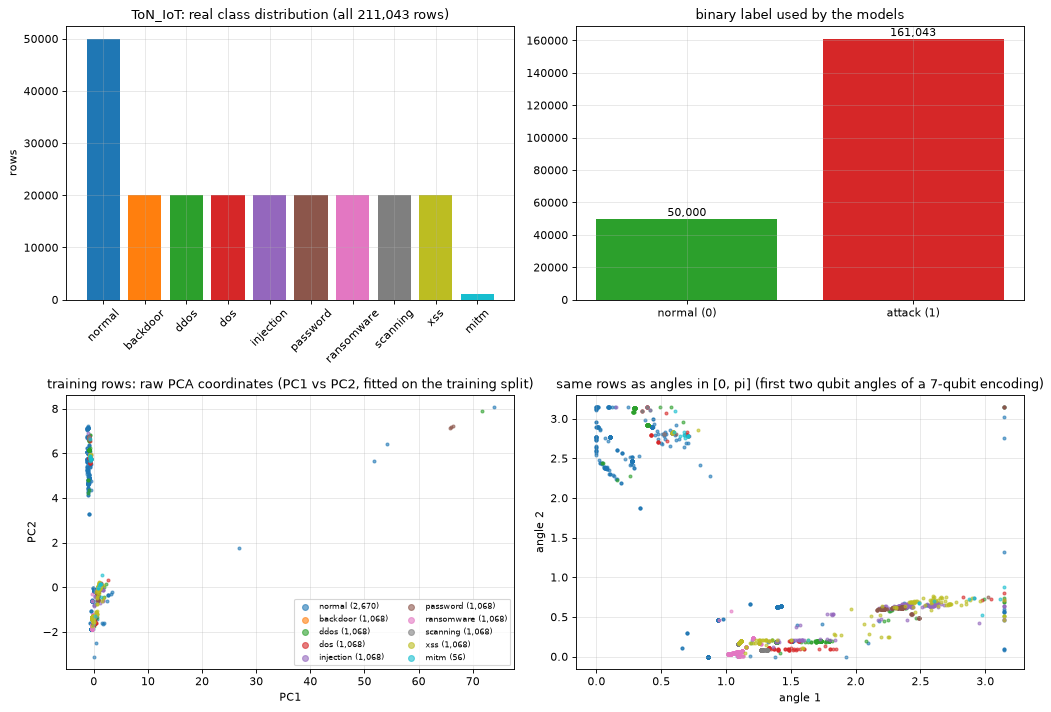

ToN_IoT: training split 11,270 rows, test split 2,818 rows (paper: 11,270 / 2,818); attack share of the test split 76.30 %


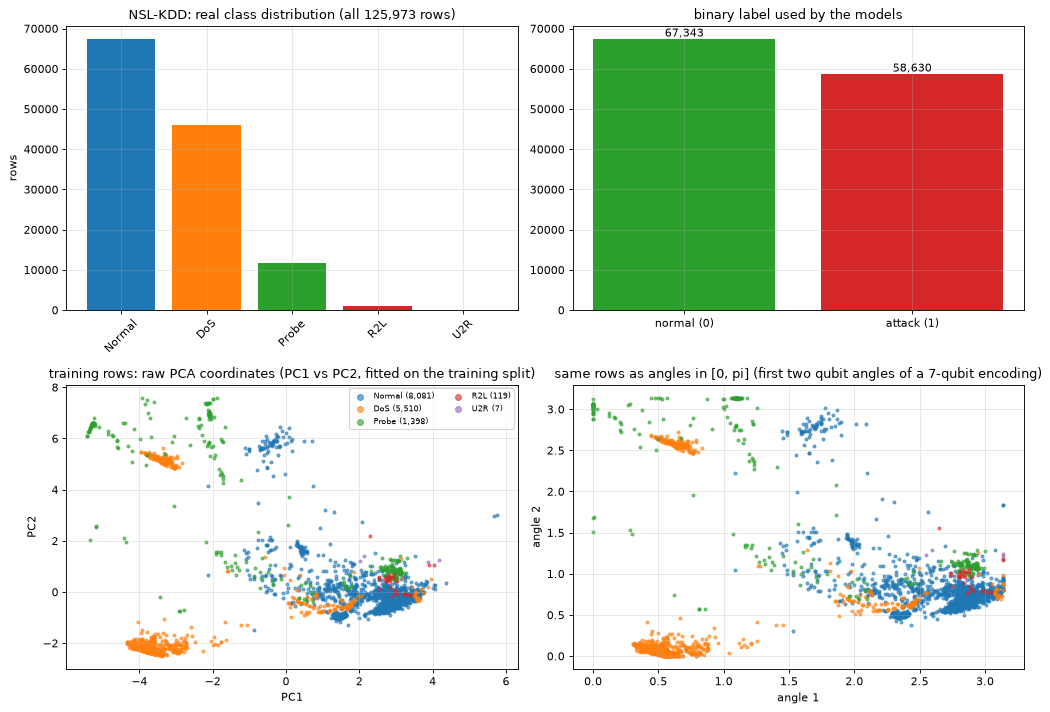

NSL-KDD: training split 15,115 rows, test split 3,779 rows (paper: 15,114 / 3,780); attack share of the test split 46.55 %


In [8]:
fam_order = {ds: list(pd.Series(DATA[ds]["fam"]).value_counts().index) for ds in DS}
palette = plt.get_cmap("tab10")
fam_color = {ds: {f: palette(i % 10) for i, f in enumerate(fam_order[ds])} for ds in DS}

def explore(ds):
    d = DATA[ds]; y, fam = d["y"], d["fam"]
    tr, te = make_split(ds, SEEDS[0])
    Z7tr, _ = prep(ds, tr, te, 7, math.pi)                               # angles that a 7-qubit circuit would receive
    P, _ = pca_coords(ds, tr, te, 7)                                      # raw PCA coordinates (after signed log1p + standardisation), fitted on the training split
    sel = np.random.default_rng(SEED).choice(len(tr), size=min(3000, len(tr)), replace=False)
    fig, ax = plt.subplots(2, 2, figsize=(13, 9))
    counts = pd.Series(fam).value_counts()
    ax[0, 0].bar(counts.index, counts.values, color=[fam_color[ds][f] for f in counts.index]); ax[0, 0].set_title(f"{ds}: real class distribution (all {len(fam):,} rows)")
    ax[0, 0].tick_params(axis="x", rotation=45); ax[0, 0].set_ylabel("rows")
    bc = np.bincount(y); ax[0, 1].bar(["normal (0)", "attack (1)"], bc, color=["tab:green", "tab:red"]); ax[0, 1].set_title("binary label used by the models")
    for k, v in enumerate(bc): ax[0, 1].text(k, v, f"{v:,}", ha="center", va="bottom")
    for f in fam_order[ds]:
        m = fam[tr][sel] == f
        ax[1, 0].scatter(P[sel][m, 0], P[sel][m, 1], s=7, alpha=0.6, color=fam_color[ds][f], label=f"{f} ({(fam[tr] == f).sum():,})")
        ax[1, 1].scatter(Z7tr[sel][m, 0], Z7tr[sel][m, 1], s=7, alpha=0.6, color=fam_color[ds][f])
    ax[1, 0].set_title("training rows: raw PCA coordinates (PC1 vs PC2, fitted on the training split)"); ax[1, 0].set_xlabel("PC1"); ax[1, 0].set_ylabel("PC2")
    ax[1, 1].set_title("same rows as angles in [0, pi] (first two qubit angles of a 7-qubit encoding)"); ax[1, 1].set_xlabel("angle 1"); ax[1, 1].set_ylabel("angle 2")
    ax[1, 0].legend(fontsize=7, markerscale=2, ncol=2)
    plt.tight_layout(); plt.show()
    print(f"{ds}: training split {len(tr):,} rows, test split {len(te):,} rows (paper: {'11,270 / 2,818' if ds == 'ToN_IoT' else '15,114 / 3,780'}); "
          f"attack share of the test split {100 * y[te].mean():.2f} %")
for ds in DS:
    explore(ds)

**What the plots show.** ToN_IoT has ten real classes (normal plus nine attack types); in two PCA dimensions several attack types overlap strongly, which is why the paper needs 6 to 7 qubits to reach 94 to 96 %. NSL-KDD's two dominant families (normal and DoS) are partly separable in the first two components, while R2L and U2R are tiny. After the `[0, pi]` rescaling the cloud is the same, only squeezed into the box that the rotation gates use.

## 2. Preprocessing, kernel bandwidth and classical baselines

### 2.1 Kernel bandwidth (angle range)

The paper only says "normalised". For a quantum kernel the scale of the angles acts like the bandwidth of a classical RBF kernel, so it matters. As prescribed by the project conventions it is chosen on a **validation split of the training data only** (never on the test split), using the paper's headline 7-qubit `ZFeatureMap` circuit with the exact kernel, and then used for every circuit of that dataset (`# CHOICE`).

In [9]:
AMAX = {}
def tune_amax(ds):
    y = DATA[ds]["y"]; tr, _ = make_split(ds, SEEDS[0])
    itr, iva = train_test_split(tr, test_size=0.2, stratify=y[tr], random_state=SEEDS[0])
    iva = take(iva, y, 1500, SEEDS[0]); scores = {}
    for a in AMAX_GRID:
        Ztr, Zva = prep(ds, itr, iva, 7, a)
        algorithm_globals.random_seed = SEEDS[0]
        m = BatchPegasos(quantum_kernel=BatchedStatevectorKernel(feature_map("Z", 7, 2)), C=1000, num_steps=100, seed=SEEDS[0]).fit(Ztr, y[itr])
        scores[round(a / math.pi, 2)] = accuracy_score(y[iva], m.predict(Zva))
    best = max(scores, key=scores.get)
    return best * math.pi, scores
t0 = time.time()
for ds in DS:
    AMAX[ds], sc_ = tune_amax(ds)
    print(f"{ds}: validation accuracy by angle range (multiples of pi) {({k: round(v, 4) for k, v in sc_.items()})} -> a_max = {AMAX[ds] / math.pi:.2f} pi")
print(f"({time.time() - t0:.0f} s)")

ToN_IoT: validation accuracy by angle range (multiples of pi) {0.5: 0.876, 1.0: 0.9407, 2.0: 0.924} -> a_max = 1.00 pi


NSL-KDD: validation accuracy by angle range (multiples of pi) {0.5: 0.952, 1.0: 0.9367, 2.0: 0.888} -> a_max = 0.50 pi
(12 s)


### 2.2 Classical baselines on exactly the same inputs (paper Table 19)

SVM, XGBoost, random forest and a small neural network receive the same PCA features (same split, same scaling, same number of components as qubits) as the quantum models. These runs use the paper-sized train/test sets and the first seed.

model         NN     RF    SVM  XGBoost
dataset q                              
NSL-KDD 3  96.59  98.70  96.82    98.47
        5  97.12  99.13  97.99    98.92
        7  98.17  99.29  98.36    99.34
ToN_IoT 3  96.20  99.15  91.09    98.86
        5  96.42  99.36  96.20    99.08
        7  98.69  99.43  98.23    99.36

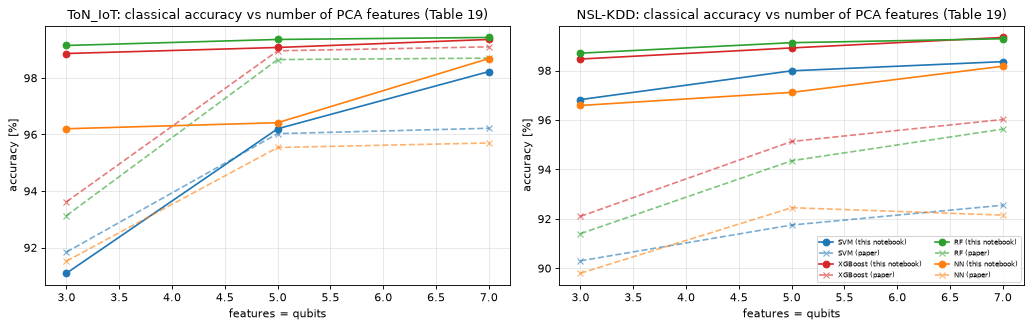

(80 s)


In [10]:
CLASSIFIERS = {
    "SVM": lambda s: SVC(kernel="rbf", C=1.0, random_state=s),
    "XGBoost": lambda s: XGBClassifier(n_estimators=100, random_state=s, n_jobs=2, eval_metric="logloss", verbosity=0),
    "RF": lambda s: RandomForestClassifier(100, random_state=s, n_jobs=2),
    "NN": lambda s: MLPClassifier((64, 32), max_iter=200, early_stopping=True, n_iter_no_change=8, random_state=s),
}
t0 = time.time()
for ds in DS:
    y = DATA[ds]["y"]; tr, te = make_split(ds, SEEDS[0])
    for q in CLASSICAL_Q:
        Ztr, Zte = prep(ds, tr, te, q, AMAX[ds])
        for name, mk in CLASSIFIERS.items():
            t1 = time.time(); m = mk(SEEDS[0]).fit(Ztr, y[tr]); p = m.predict(Zte)
            log(kind="classical", model=name, dataset=ds, q=q, seed=SEEDS[0], t_fit=time.time() - t1, **metrics(y[te], p))
cl = pd.DataFrame([r for r in RES if r["kind"] == "classical"])
tab = cl.pivot_table(index=["dataset", "q"], columns="model", values="acc").round(2)
display(tab)
fig, ax = plt.subplots(1, 2, figsize=(13, 4.2))
for a_, ds in zip(ax, DS):
    for name, c in zip(CLASSIFIERS, ["tab:blue", "tab:red", "tab:green", "tab:orange"]):
        s = cl[(cl.dataset == ds) & (cl.model == name)].sort_values("q")
        a_.plot(s.q, s.acc, "-o", color=c, label=f"{name} (this notebook)")
        qs = [q for q in CLASSICAL_Q]; a_.plot(qs, [T19[q][name][DSI[ds]] for q in qs], "--x", color=c, alpha=0.6, label=f"{name} (paper)")
    a_.set_title(f"{ds}: classical accuracy vs number of PCA features (Table 19)"); a_.set_xlabel("features = qubits"); a_.set_ylabel("accuracy [%]")
a_.legend(fontsize=6, ncol=2); plt.tight_layout(); plt.show()
print(f"({time.time() - t0:.0f} s)")

## Quantum Circuit Architecture

This section draws the circuits that the notebook really runs, taken from the very objects used later: the kernel objects of the Pegasos-QSVC, the circuit inside Qiskit's `VQC`, and the circuit of the quantum layer of the hybrid network. For each one the number of qubits, the depth (after writing Qiskit's composite blocks out as elementary gates), the number of free parameters and the CNOT count after transpilation for `FakePerth` (the 7-qubit device coupling map shared by the three fake backends) are printed.

### Assumptions where the paper omits circuit details
* **Pauli feature maps**: the entanglement pattern is not stated, the Qiskit default (`full`) is used. `X`, `Y`, `Z` (single-qubit strings) therefore give no entanglement; two-qubit strings (`XX`, `ZZ`, `YY`, ...) give one two-qubit rotation per qubit pair.
* **ZZFeatureMap** uses the entanglement named in the configuration (`linear`, `full`, `circular`).
* **Ansatz**: `RealAmplitudes` (RY + CX, `reverse_linear` entanglement) and `EfficientSU2` (RY, RZ + CX, `reverse_linear`) with Qiskit defaults and `reps` as in the table.
* **VQC measurement**: Qiskit's `VQC` measures all qubits and maps the bitstring to a class by parity; one-hot labels.
* **HQNN quantum layer**: feature map + ansatz, observable `Z...Z` on all qubits (Fig. 3 of the paper does not give the observable), inputs are the outputs of the second linear layer.
* **Noisy runs**: transpilation with optimisation level 1 for the fake device, Qiskit's `VF2` layout choice, basis gates `cx, rz, sx, x`.

### Drawings

QSVC ideal kernel: 7-qubit ZFeatureMap, r=2 (this feature map is what the statevector simulator runs for each row)
  qubits: 7 | depth (elementary gates): 4 | free parameters: 7 | after transpiling for FakePerth: depth 8, CX 0


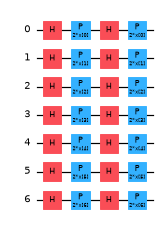

QSVC noisy kernel circuit U(x) then U(y)^dagger with measurement (14 free parameters: 7 for x, 7 for y)
  qubits: 7 | depth (elementary gates): 9 | free parameters: 14 | after transpiling for FakePerth: depth 17, CX 0


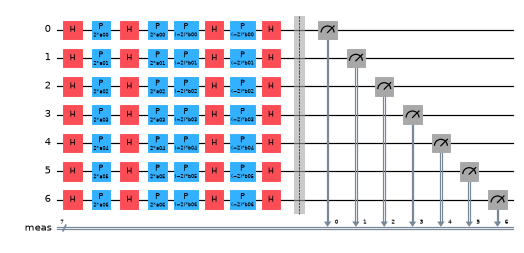

transpiled for FakePerth (what the noisy simulator executes): depth 17 | CX 0 | ops {'rz': 84, 'sx': 28, 'measure': 7, 'barrier': 1}


In [11]:
DRAW_BASIS = ["h", "p", "rz", "ry", "rx", "sx", "sxdg", "s", "sdg", "cx", "x"]
def show_circuit(qc, title, fold=32, scale=0.55, backend="FakePerth", trainable=None):
    dec = transpile(qc, basis_gates=DRAW_BASIS, optimization_level=0)       # Qiskit's composite blocks written out as elementary gates (readable drawing)
    tq = transpile(dec, FAKE[backend], optimization_level=1, seed_transpiler=SEED)
    print(f"{title}\n  qubits: {qc.num_qubits} | depth (elementary gates): {dec.depth()} | free parameters: {qc.num_parameters}"
          + (f" (trainable: {trainable})" if trainable is not None else "")
          + f" | after transpiling for {backend}: depth {tq.depth()}, CX {tq.count_ops().get('cx', 0)}")
    display(dec.draw("mpl", fold=fold, scale=scale))
    plt.close("all")
    return dict(circuit=title, qubits=qc.num_qubits, depth=dec.depth(), params=qc.num_parameters, cx_transpiled=tq.count_ops().get("cx", 0), depth_transpiled=tq.depth())

ARCH = []
# 1. Pegasos-QSVC: the kernel circuit for the paper's headline configuration, ideal and noisy
fm_demo = feature_map("Z", 7, 2)
kid = BatchedStatevectorKernel(fm_demo)
assert kid.executed.data[-1].operation.name == "save_statevector" and len(kid.executed.data) == len(fm_demo.data) + 1   # executed = feature map + save
ARCH.append(show_circuit(fm_demo, "QSVC ideal kernel: 7-qubit ZFeatureMap, r=2 (this feature map is what the statevector simulator runs for each row)"))
knz = NoisyFidelityKernel(feature_map("Z", 7, 2), "FakePerth")
ARCH.append(show_circuit(knz.logical, "QSVC noisy kernel circuit U(x) then U(y)^dagger with measurement (14 free parameters: 7 for x, 7 for y)"))
print("transpiled for FakePerth (what the noisy simulator executes): depth", knz.executed.depth(), "| CX", knz.cx, "| ops", dict(knz.executed.count_ops()))

QSVC feature map: 6-qubit ZZFeatureMap (linear), r=1
  qubits: 6 | depth (elementary gates): 17 | free parameters: 6 | after transpiling for FakePerth: depth 20, CX 11


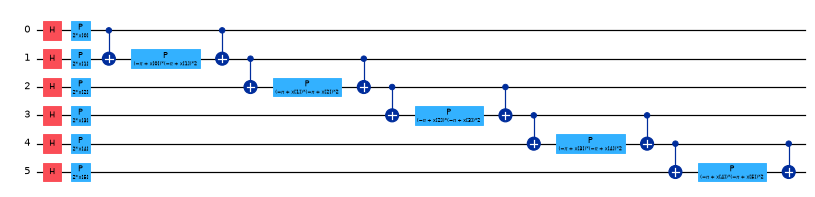

QSVC feature map: 4-qubit PauliFeatureMap [Z,YY] (full entanglement), r=1
  qubits: 4 | depth (elementary gates): 27 | free parameters: 4 | after transpiling for FakePerth: depth 32, CX 18


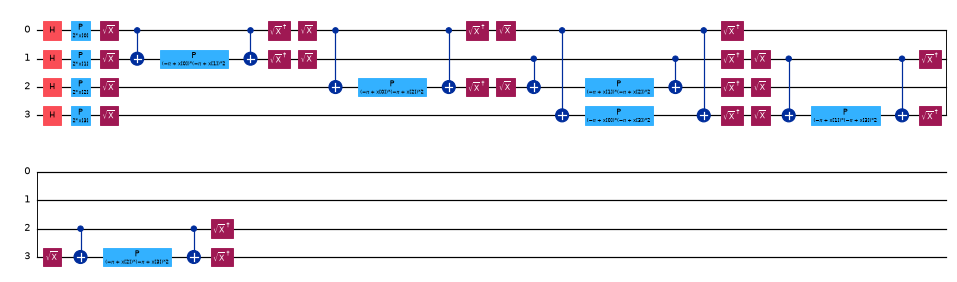

In [12]:
# 2./3. Entangling feature maps of the Pegasos-QSVC configurations that are run noisy
ARCH.append(show_circuit(feature_map("ZZ-linear", 6, 1), "QSVC feature map: 6-qubit ZZFeatureMap (linear), r=1"))
ARCH.append(show_circuit(feature_map("Z,YY", 4, 1), "QSVC feature map: 4-qubit PauliFeatureMap [Z,YY] (full entanglement), r=1"))

VQC object circuit ops: {'ry': 9, 'cx': 4, 'h': 3, 'sx': 3, 'p': 3, 'sxdg': 3}
VQC 3q Pauli[Y] + RealAmplitudes r=2
  qubits: 3 | depth (elementary gates): 11 | free parameters: 12 (trainable: 9) | after transpiling for FakePerth: depth 19, CX 4


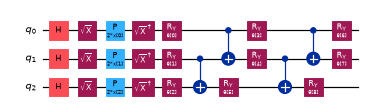

VQC object circuit ops: {'ry': 9, 'rz': 9, 'cx': 8, 'p': 5, 'h': 3}
VQC 3q ZZ(Linear) + EfficientSU2 r=2
  qubits: 3 | depth (elementary gates): 18 | free parameters: 21 (trainable: 18) | after transpiling for FakePerth: depth 29, CX 8


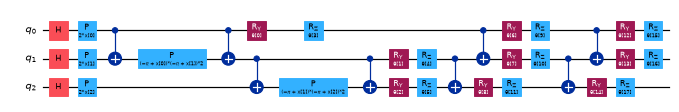

In [13]:
# 4. VQC circuits (the circuit stored inside Qiskit's VQC object: feature map + ansatz + measurement)
for key in ["PY3", "ZZ3"]:
    c = VQC_CFG[key]
    v = VQC(feature_map=feature_map(c["fm"], c["q"], 1), ansatz=build_ansatz(c["ans"], c["q"], c["reps"]))
    print("VQC object circuit ops:", dict(v.circuit.count_ops()))
    ARCH.append(show_circuit(v.circuit, f"VQC {c['label']}", trainable=v.ansatz.num_parameters))

HQNN quantum layer 3q Pauli[Z,YY] + EfficientSU2 r=2 (observable Z^3)
  qubits: 3 | depth (elementary gates): 27 | free parameters: 21 (trainable: 18) | after transpiling for FakePerth: depth 39, CX 13


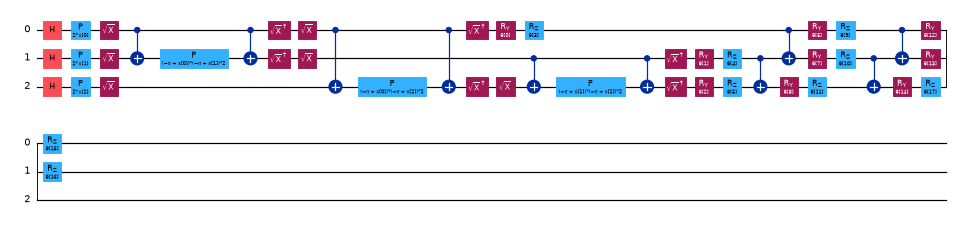

HQNN quantum layer 6q ZZ(Full) + EfficientSU2 r=2 (observable Z^6)
  qubits: 6 | depth (elementary gates): 42 | free parameters: 42 (trainable: 36) | after transpiling for FakePerth: depth 107, CX 73


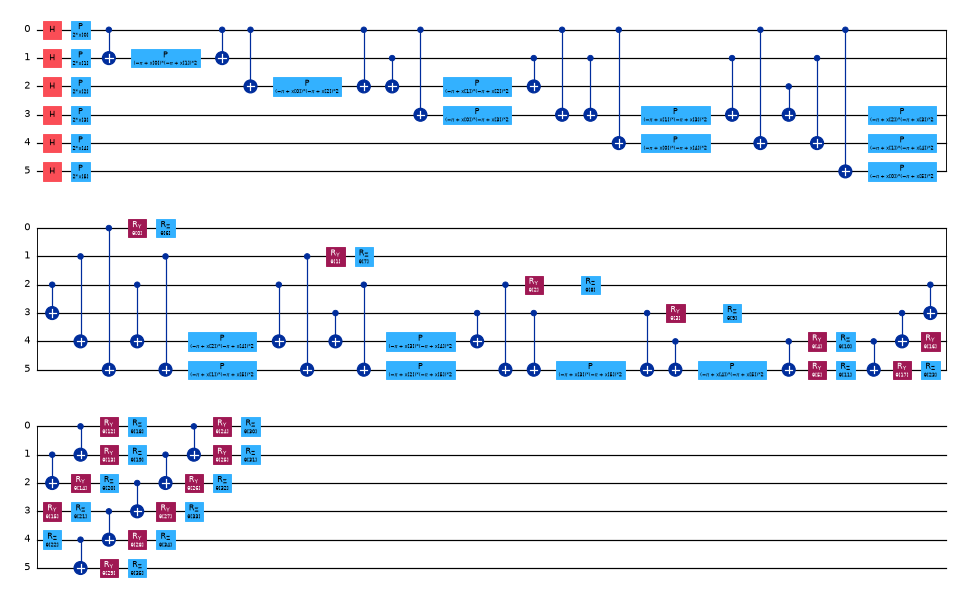

Classical part of every HQNN: Linear(q, 8) -> ReLU -> Linear(8, q) -> quantum layer (inputs = q rotation angles, weights = ansatz angles) -> <Z...Z> in [-1, 1]; class = sign


,circuit,qubits,depth,params,cx_transpiled,depth_transpiled
0,"QSVC ideal kernel: 7-qubit ZFeatureMap, r=2 (t...",7,4,7,0,8
1,QSVC noisy kernel circuit U(x) then U(y)^dagge...,7,9,14,0,17
2,QSVC feature map: 6-qubit ZZFeatureMap (linear...,6,17,6,11,20
3,"QSVC feature map: 4-qubit PauliFeatureMap [Z,Y...",4,27,4,18,32
4,VQC 3q Pauli[Y] + RealAmplitudes r=2,3,11,12,4,19
5,VQC 3q ZZ(Linear) + EfficientSU2 r=2,3,18,21,8,29
6,"HQNN quantum layer 3q Pauli[Z,YY] + EfficientS...",3,27,21,13,39
7,HQNN quantum layer 6q ZZ(Full) + EfficientSU2 ...,6,42,42,73,107


In [14]:
# 5. HQNN quantum layer: feature map + ansatz, observable Z...Z (the classical Linear-ReLU-Linear part is drawn as text below)
for key in ["H3q", "H6q"]:
    c = HQNN_CFG[key]
    fm_h = feature_map(c["fm"], c["q"], c["fr"]); an_h = build_ansatz(c["ans"], c["q"], c["ar"])
    ARCH.append(show_circuit(fm_h.compose(an_h), f"HQNN quantum layer {c['label']} (observable Z^{c['q']})", trainable=an_h.num_parameters))
print("Classical part of every HQNN: Linear(q, 8) -> ReLU -> Linear(8, q) -> quantum layer (inputs = q rotation angles, weights = ansatz angles) -> <Z...Z> in [-1, 1]; class = sign")
display(pd.DataFrame(ARCH))

## 3. Pegasos-QSVC (paper Section 5.1)

A quantum kernel `k(x, y) = |<phi(x)|phi(y)>|^2` measures how similar two connections look after the feature map `phi` has loaded them into a quantum state. **Pegasos** is a stochastic sub-gradient solver for the SVM objective: in each of `steps` iterations it draws one random training row, checks whether the margin condition `y * (C / t) * sum_j alpha_j y_j k(x, x_j) < 1` is violated and, if so, adds that row to the support set. After 100 steps there are only about 20 to 30 support vectors, which is why training is cheap and prediction (one kernel value per support vector and test row) dominates the cost.

### 3.1 Correctness checks of the helper classes
Before trusting any number, the three kernel implementations and the batched Pegasos decision function are checked against the references.

In [15]:
fm_chk = feature_map("ZZ-linear", 4, 1)
xs, ys_ = rng.uniform(0, math.pi, (6, 4)), rng.uniform(0, math.pi, (5, 4))
K_batched = BatchedStatevectorKernel(fm_chk).evaluate(xs, ys_)
K_qiskit = FidelityStatevectorKernel(feature_map=fm_chk).evaluate(xs, ys_)
K_hand = np.array([[abs(Statevector(fm_chk.assign_parameters(a)).inner(Statevector(fm_chk.assign_parameters(b)))) ** 2 for b in ys_] for a in xs])
assert np.allclose(K_batched, K_qiskit) and np.allclose(K_batched, K_hand)
print("exact kernel: batched Aer == FidelityStatevectorKernel == hand-computed |<phi(a)|phi(b)>|^2  ->  OK")

# batched Pegasos decision function equals the parent's per-sample implementation
ds = "ToN_IoT"; y = DATA[ds]["y"]; tr, te = make_split(ds, SEEDS[0]); tr_s, te_s = take(tr, y, 300, SEEDS[0]), take(te, y, 25, SEEDS[0])
Ztr_, Zte_ = prep(ds, tr_s, te_s, 4, AMAX[ds])
algorithm_globals.random_seed = SEEDS[0]
m_chk = BatchPegasos(quantum_kernel=BatchedStatevectorKernel(feature_map("Z", 4, 1)), C=1000, num_steps=40, seed=SEEDS[0]).fit(Ztr_, y[tr_s])
assert np.allclose(m_chk.decision_function(Zte_), PegasosQSVC.decision_function(m_chk, Zte_))
print("BatchPegasos.decision_function == PegasosQSVC.decision_function on 25 test rows  ->  OK")

# the noisy kernel with the noise switched off must reproduce the exact kernel up to shot noise
fm_n = feature_map("Z,YY", 3, 1); kn = NoisyFidelityKernel(fm_n, "FakePerth")
ideal_sim = AerSimulator(method="statevector"); a_, b_ = xs[:3, :3], ys_[:3, :3]
vals = np.concatenate([np.repeat(a_, 3, axis=0), np.tile(b_, (3, 1))], axis=1)
names = [f"a{i:02d}" for i in range(3)] + [f"b{i:02d}" for i in range(3)]
binds = {p: vals[:, names.index(p.name)].tolist() for p in kn.executed.parameters}
cnt = ideal_sim.run(kn.executed, parameter_binds=[binds], shots=20000, seed_simulator=1).result()
K_noiseless_circuit = np.array([cnt.get_counts(i).get("000", 0) / 20000 for i in range(9)]).reshape(3, 3)
K_ref = BatchedStatevectorKernel(fm_n).evaluate(a_, b_)
print("transpiled compute-uncompute circuit without noise vs exact kernel, max abs difference:", float(np.abs(K_noiseless_circuit - K_ref).max()))
assert np.abs(K_noiseless_circuit - K_ref).max() < 0.03

exact kernel: batched Aer == FidelityStatevectorKernel == hand-computed |<phi(a)|phi(b)>|^2  ->  OK


BatchPegasos.decision_function == PegasosQSVC.decision_function on 25 test rows  ->  OK


transpiled compute-uncompute circuit without noise vs exact kernel, max abs difference: 0.005667061229816472


### 3.2 Training and evaluating one configuration
`run_qsvc` is the single entry point: it draws the paper-sized split for a given seed, fits the preprocessing on the training rows, trains `BatchPegasos` with the ideal or a noisy kernel, and logs accuracy / precision / recall / F1 (attack = positive class), the number of support vectors, the CNOT count of the transpiled kernel circuit and the timings.

In [16]:
QCACHE = {}
def run_qsvc(ds, key, seed, C=1000, steps=100, backend=None, n_test=None):
    ck = (ds, key, seed, C, steps, backend, n_test)
    if ck in QCACHE:
        return QCACHE[ck]
    c = QSVC_CFG[key]; y = DATA[ds]["y"]
    tr, te = make_split(ds, seed); te = take(te, y, n_test, seed)
    Ztr, Zte = prep(ds, tr, te, c["q"], AMAX[ds])
    fm = feature_map(c["fm"], c["q"], c["r"])
    kern = BatchedStatevectorKernel(fm) if backend is None else NoisyFidelityKernel(fm, backend, SHOTS, seed)
    cx = NoisyFidelityKernel(fm, "FakePerth").cx if backend is None else kern.cx          # CNOTs of the compute-uncompute circuit on the 7-qubit device
    algorithm_globals.random_seed = seed
    t0 = time.time(); m = BatchPegasos(quantum_kernel=kern, C=C, num_steps=steps, seed=seed).fit(Ztr, y[tr]); t_fit = time.time() - t0
    t0 = time.time(); p = m.predict(Zte); t_pred = time.time() - t0
    row = log(kind="qsvc", model="Pegasos-QSVC", dataset=ds, key=key, backend=backend or "ideal", seed=seed, C=C, steps=steps, n_train=len(tr), n_test=len(te),
              n_sv=len(m._alphas), cx=cx, t_fit=t_fit, t_pred=t_pred, **metrics(y[te], p))
    QCACHE[ck] = row
    return row
r = run_qsvc("ToN_IoT", "Z7r2", SEEDS[0])
print({k: (round(v, 2) if isinstance(v, float) else v) for k, v in r.items()})

{'kind': 'qsvc', 'model': 'Pegasos-QSVC', 'dataset': 'ToN_IoT', 'key': 'Z7r2', 'backend': 'ideal', 'seed': 12345, 'C': 1000, 'steps': 100, 'n_train': 11270, 'n_test': 2818, 'n_sv': 16, 'cx': 0, 't_fit': 0.51, 't_pred': 1.46, 'acc': 92.9, 'prec': 94.24, 'rec': 96.6, 'f1': 95.41}


### 3.3 Regularisation `C` and number of steps (paper Table 11)
The paper does not say which circuit Table 11 belongs to; the headline 7-qubit `ZFeatureMap` (r=2) on ToN_IoT is used here (`# CHOICE`). The signature behaviour to check: large `C` works, small `C` collapses to "predict attack for everything" (accuracy = share of attacks in the test set, recall 100 %).

In [17]:
rows = []
for C in C_SWEEP:
    r = run_qsvc("ToN_IoT", "Z7r2", SEEDS[0], C=C)
    p = TABLE11[C]
    rows.append({"C": C, "acc": r["acc"], "prec": r["prec"], "rec": r["rec"], "F1": r["f1"], "support vectors": r["n_sv"],
                 "paper acc": p[0], "paper prec": p[1], "paper rec": p[2], "paper F1": p[3]})
display(pd.DataFrame(rows).round(2))
rows = []
for st in STEPS_SWEEP:
    r = run_qsvc("ToN_IoT", "Z7r2", SEEDS[0], steps=st)
    rows.append({"steps": st, "acc": r["acc"], "F1": r["f1"], "train time [s]": r["t_fit"], "predict time [s]": r["t_pred"], "support vectors": r["n_sv"]})
display(pd.DataFrame(rows).round(2))
print("paper: 100 steps is the best trade-off between accuracy and time; 20/50/100/200/500 were tried")

,C,acc,prec,rec,F1,support vectors,paper acc,paper prec,paper rec,paper F1
0,1000,92.90,94.24,96.60,95.41,16,92.25,92.77,97.18,94.92
1,100,92.65,93.66,96.93,95.27,24,91.61,92.02,97.18,94.53
2,10,87.90,86.63,99.49,92.62,55,79.16,89.48,81.65,85.39
3,1,76.30,76.30,100.00,86.55,94,74.56,74.56,100.00,85.42


,steps,acc,F1,train time [s],predict time [s],support vectors
0,20,84.74,90.22,0.12,2.48,2
1,100,92.90,95.41,0.51,1.46,16


paper: 100 steps is the best trade-off between accuracy and time; 20/50/100/200/500 were tried


### 3.4 Ideal simulation of the paper's best configurations (Table 12)
For every selected configuration and every seed the full paper-sized train/test sets are used (statevector kernel, no noise). The table shows mean +- std over `SEEDS` next to the paper's value.

,configuration,dataset,acc,acc std,F1,F1 std,paper acc,paper F1,d acc,fit [s],predict [s],CX (device circuit)
0,q=7 ZFeatureMap r=2,ToN_IoT,92.90,0.0,95.41,0.0,95.44,96.94,-2.54,0.51,1.46,0
1,q=7 ZFeatureMap r=2,NSL-KDD,94.63,0.0,94.21,0.0,95.80,95.23,-1.17,0.58,2.75,0
2,q=6 ZZ(Linear) r=1,ToN_IoT,91.06,0.0,94.09,0.0,94.12,96.05,-3.06,0.50,1.36,24
3,q=6 ZZ(Linear) r=1,NSL-KDD,83.73,0.0,78.82,0.0,90.21,89.43,-6.48,0.56,2.81,24
4,"q=4 Pauli[Z,YY] r=1",ToN_IoT,90.63,0.0,93.88,0.0,93.17,95.50,-2.54,0.65,1.67,32
5,"q=4 Pauli[Z,YY] r=1",NSL-KDD,81.37,0.0,75.38,0.0,92.18,91.04,-10.81,0.75,3.85,32


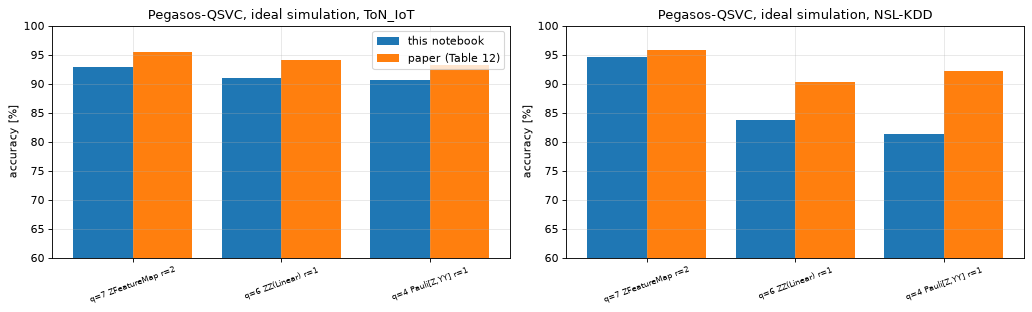

(21 s)


In [18]:
t0 = time.time(); rows = []
for key in QSVC_NOISELESS:
    for ds in DS:
        rr = [run_qsvc(ds, key, s) for s in SEEDS]
        a, f = np.array([r["acc"] for r in rr]), np.array([r["f1"] for r in rr])
        pa, pf = QSVC_CFG[key]["ideal"][ds]
        rows.append({"configuration": QSVC_CFG[key]["label"], "dataset": ds, "acc": a.mean(), "acc std": a.std(), "F1": f.mean(), "F1 std": f.std(),
                     "paper acc": pa, "paper F1": pf, "d acc": a.mean() - pa, "fit [s]": np.mean([r["t_fit"] for r in rr]), "predict [s]": np.mean([r["t_pred"] for r in rr]),
                     "CX (device circuit)": rr[0]["cx"]})
T12 = pd.DataFrame(rows); display(T12.round(2))
fig, ax = plt.subplots(1, 2, figsize=(13, 4))
for a_, ds in zip(ax, DS):
    s = T12[T12.dataset == ds]; x = np.arange(len(s))
    a_.bar(x - 0.2, s["acc"], 0.4, yerr=s["acc std"], label="this notebook"); a_.bar(x + 0.2, s["paper acc"], 0.4, label="paper (Table 12)")
    a_.set_xticks(x); a_.set_xticklabels(s["configuration"], rotation=20, fontsize=7); a_.set_ylim(60, 100); a_.set_ylabel("accuracy [%]"); a_.set_title(f"Pegasos-QSVC, ideal simulation, {ds}")
ax[0].legend(); plt.tight_layout(); plt.show()
print(f"({time.time() - t0:.0f} s)")

### 3.5 Noisy simulation on the fake IBM devices (paper Table 13)
The kernel entries are now estimated with 1024 shots on a density-matrix simulator that contains the full noise model of the device snapshot (gate errors, thermal relaxation, readout error), after transpiling the compute-uncompute circuit to the device's coupling map. Each noisy kernel evaluation is a separate circuit run, so the noisy runs use a **subset of the test rows** and (in FAST_MODE) fewer Pegasos steps. The "ideal on the same rows" line uses the same rows, steps and seed with the exact kernel, so the two are directly comparable.

Note on readout: `FakeLagosV2` carries a very large readout error (up to 46 % on one qubit, paper Table 4). The probability of reading `0...0` is therefore scaled down for *every* kernel entry, which shrinks the kernel towards zero but does not change its ranking much; the Pegasos decision function then depends mostly on the (still informative) differences between entries.

In [19]:
t0 = time.time(); rows = []
for key in QSVC_NOISY:
    for ds in DS:
        ref = run_qsvc(ds, key, SEEDS[0], steps=NOISY_STEPS, backend=None, n_test=NOISY_N_TEST)
        rows.append({"configuration": QSVC_CFG[key]["label"], "dataset": ds, "backend": "ideal (same rows)", "acc": ref["acc"], "F1": ref["f1"], "paper acc": QSVC_CFG[key]["ideal"][ds][0],
                     "paper F1": QSVC_CFG[key]["ideal"][ds][1], "CX": ref["cx"], "time [s]": ref["t_fit"] + ref["t_pred"]})
        for bk in NOISY_BACKENDS:
            r = run_qsvc(ds, key, SEEDS[0], steps=NOISY_STEPS, backend=bk, n_test=NOISY_N_TEST); r["acc_ideal_ref"] = ref["acc"]
            pa, pf = QSVC_NOISY_PAPER[key][bk][ds]
            rows.append({"configuration": QSVC_CFG[key]["label"], "dataset": ds, "backend": bk, "acc": r["acc"], "F1": r["f1"], "paper acc": pa, "paper F1": pf,
                         "CX": r["cx"], "time [s]": r["t_fit"] + r["t_pred"]})
            print(f"  {key:9s} {ds:8s} {bk:14s} acc {r['acc']:.1f} F1 {r['f1']:.1f}  (n_test={r['n_test']}, steps={NOISY_STEPS}, {r['t_fit'] + r['t_pred']:.0f} s)", flush=True)
T13 = pd.DataFrame(rows); display(T13.round(2))
print(f"({time.time() - t0:.0f} s)")

  Z7r2      ToN_IoT  FakeLagosV2    acc 86.7 F1 90.9  (n_test=30, steps=50, 47 s)


  Z7r2      ToN_IoT  FakePerth      acc 86.7 F1 90.9  (n_test=30, steps=50, 44 s)


  Z7r2      NSL-KDD  FakeLagosV2    acc 90.0 F1 88.9  (n_test=30, steps=50, 43 s)


  Z7r2      NSL-KDD  FakePerth      acc 90.0 F1 88.9  (n_test=30, steps=50, 29 s)


,configuration,dataset,backend,acc,F1,paper acc,paper F1,CX,time [s]
0,q=7 ZFeatureMap r=2,ToN_IoT,ideal (same rows),86.67,90.91,95.44,96.94,0,0.38
1,q=7 ZFeatureMap r=2,ToN_IoT,FakeLagosV2,86.67,90.91,93.24,95.54,0,47.12
2,q=7 ZFeatureMap r=2,ToN_IoT,FakePerth,86.67,90.91,94.31,96.21,0,44.11
3,q=7 ZFeatureMap r=2,NSL-KDD,ideal (same rows),93.33,92.86,95.80,95.23,0,0.46
4,q=7 ZFeatureMap r=2,NSL-KDD,FakeLagosV2,90.00,88.89,94.66,94.19,0,43.41
5,q=7 ZFeatureMap r=2,NSL-KDD,FakePerth,90.00,88.89,94.74,94.28,0,28.84


(171 s)


### 3.6 How much does noise change the kernel itself?
The classification runs above use few test rows, so their noisy-versus-ideal differences are dominated by sampling error. A cleaner view of the noise is to compare the **kernel values** directly: for a fixed set of 8 x 8 pairs of real ToN_IoT rows the ideal kernel `K_ideal` is compared with the noisy kernel `K_noisy` of each backend. Reported: the mean absolute error, the ratio of the mean kernel values (readout and gate errors shrink `P(0...0)`), and the Pearson correlation (does the noisy kernel still rank pairs like the ideal one?). Three circuits of increasing CNOT count are used.

In [20]:
def kernel_noise(key, backend, n=8, ds="ToN_IoT"):
    c = QSVC_CFG[key]; tr, te = make_split(ds, SEEDS[0]); Ztr, Zte = prep(ds, tr, te, c["q"], AMAX[ds])
    A, B = Zte[:n], Ztr[:n]; fm = feature_map(c["fm"], c["q"], c["r"])
    Ki = BatchedStatevectorKernel(fm).evaluate(A, B); kn = NoisyFidelityKernel(fm, backend, SHOTS, SEEDS[0]); Kn = kn.evaluate(A, B)
    return dict(circuit=c["label"], backend=backend, cx=kn.cx, depth=kn.depth, mean_abs_err=float(np.abs(Kn - Ki).mean()),
                mean_ratio=float(Kn.mean() / Ki.mean()), pearson=float(np.corrcoef(Kn.ravel(), Ki.ravel())[0, 1]))
t0 = time.time()
KN = pd.DataFrame([kernel_noise(k, b) for k in ["Z7r2", "ZZlin6r1", "ZYY4r1"] for b in BACKENDS_ALL])
display(KN.round(3))
print(f"({time.time() - t0:.0f} s)  readout error of the worst qubit: Lagos 46 %, Nairobi 5.8 %, Perth 4.3 % (paper Tables 4, 6, 8)")

,circuit,backend,cx,depth,mean_abs_err,mean_ratio,pearson
0,q=7 ZFeatureMap r=2,FakeNairobiV2,0,17,0.041,0.834,0.999
1,q=7 ZFeatureMap r=2,FakeLagosV2,0,17,0.181,0.237,0.978
2,q=7 ZFeatureMap r=2,FakePerth,0,17,0.043,0.821,0.999
3,q=6 ZZ(Linear) r=1,FakeNairobiV2,22,45,0.038,0.691,0.999
4,q=6 ZZ(Linear) r=1,FakeLagosV2,22,45,0.082,0.331,0.990
5,q=6 ZZ(Linear) r=1,FakePerth,22,45,0.035,0.719,0.999
6,"q=4 Pauli[Z,YY] r=1",FakeNairobiV2,34,73,0.034,0.863,0.996
7,"q=4 Pauli[Z,YY] r=1",FakeLagosV2,34,73,0.083,0.586,0.931
8,"q=4 Pauli[Z,YY] r=1",FakePerth,34,73,0.030,0.893,0.995


(35 s)  readout error of the worst qubit: Lagos 46 %, Nairobi 5.8 %, Perth 4.3 % (paper Tables 4, 6, 8)


## 4. VQC (paper Section 5.2)

A **variational quantum classifier** encodes a row with the feature map, applies a trainable ansatz, measures all qubits and turns the bitstring into a class by parity. The 2 to 3 trainable-angle count per qubit and layer makes the model small (9 to 24 weights here), the price is a noisy, non-convex optimisation with a classical optimiser (COBYLA etc.). Training evaluates the whole training batch at every optimiser step, so the cost is `iterations x training rows` circuit executions; the paper used 11,270 training rows, here a few hundred at most (see the configuration cell).

In [21]:
VQC_HIST = {}
def make_optimizer(name, maxiter):
    return {"COBYLA": COBYLA, "SPSA": SPSA, "NELDER_MEAD": NELDER_MEAD, "POWELL": POWELL}[name](maxiter=maxiter)

def run_vqc(ds, key, seed, opt="COBYLA", backend=None, n_test=None):
    c = VQC_CFG[key]; y = DATA[ds]["y"]; tr, te = make_split(ds, seed)
    Ztr, Zte = prep(ds, tr, te, c["q"], AMAX[ds])
    s_tr = take(np.arange(len(tr)), y[tr], VQC_TRAIN, seed)                      # training subset (CHOICE: budget)
    s_te = take(np.arange(len(te)), y[te], VQC_TEST, seed)[: (n_test or VQC_TEST)]
    fm = feature_map(c["fm"], c["q"], 1); an = build_ansatz(c["ans"], c["q"], c["reps"])
    hist = []
    cb = lambda *a: hist.append(a[1] if len(a) == 2 else a[2])
    if backend is None:
        sampler, pm = AerSampler(default_shots=SHOTS, seed=seed), None
    else:
        sampler = AerSampler(default_shots=SHOTS, seed=seed, options={"backend_options": {"noise_model": NoiseModel.from_backend(FAKE[backend]), "method": "density_matrix"}})
        pm = generate_preset_pass_manager(optimization_level=1, backend=FAKE[backend], seed_transpiler=seed)
    algorithm_globals.random_seed = seed
    m = VQC(feature_map=fm, ansatz=an, optimizer=make_optimizer(opt, VQC_ITERS), sampler=sampler, pass_manager=pm, callback=cb)
    t0 = time.time(); m.fit(Ztr[s_tr], y[tr][s_tr]); t_fit = time.time() - t0
    t0 = time.time(); p = m.predict(Zte[s_te]); t_pred = time.time() - t0
    cx = transpile(fm.compose(an).decompose(reps=4), FAKE["FakePerth"], optimization_level=1, seed_transpiler=seed).count_ops().get("cx", 0)
    VQC_HIST[(ds, key, opt, backend or "ideal")] = hist
    small = slice(0, VQC_NOISY_TEST)                     # the noisy runs use these first rows of the same test subset
    return log(kind="vqc", model="VQC", dataset=ds, key=key, optimizer=opt, backend=backend or "ideal", seed=seed, n_train=len(s_tr), n_test=len(s_te),
               iters=VQC_ITERS, cx=cx, t_fit=t_fit, t_pred=t_pred, final_loss=hist[-1] if hist else np.nan,
               acc_small=100 * accuracy_score(y[te][s_te][small], p[small]), **metrics(y[te][s_te], p))
t0 = time.time(); rows = []
for key in VQC_CFGS:
    for ds in DS:
        r = run_vqc(ds, key, SEEDS[0])
        rows.append({"configuration": VQC_CFG[key]["label"], "dataset": ds, "optimizer": "COBYLA", "acc": r["acc"], "F1": r["f1"],
                     "paper acc (Table 15, ToN_IoT assumed)": VQC_CFG[key]["cobyla"] if ds == "ToN_IoT" else np.nan, "train rows": r["n_train"], "iterations": r["iters"],
                     "fit [s]": r["t_fit"]})
T15 = pd.DataFrame(rows); display(T15.round(2)); print(f"({time.time() - t0:.0f} s)")

,configuration,dataset,optimizer,acc,F1,"paper acc (Table 15, ToN_IoT assumed)",train rows,iterations,fit [s]
0,3q Pauli[Y] + RealAmplitudes r=2,ToN_IoT,COBYLA,86.0,91.08,92.13,80,20,19.97
1,3q Pauli[Y] + RealAmplitudes r=2,NSL-KDD,COBYLA,91.5,90.29,NaN,80,20,19.14


(46 s)


### 4.1 Optimiser comparison (paper Table 15)
The paper compares COBYLA, SPSA, NFT, Nelder-Mead and Powell on the same circuit. Here: the optimisers available in `qiskit-machine-learning` that the paper also used, on `3q Pauli[Y] + RealAmplitudes r=2`, ToN_IoT.

,optimizer,acc,F1,paper acc (Table 15),fit time [s],final loss
0,COBYLA,86.0,91.083,92.13,17.131,0.616


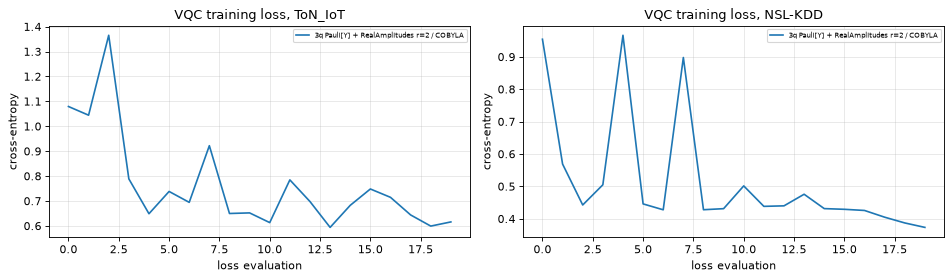

(21 s)


In [22]:
t0 = time.time(); rows = []
for opt in VQC_OPTIMIZERS:
    r = run_vqc("ToN_IoT", "PY3", SEEDS[0], opt=opt)
    rows.append({"optimizer": opt, "acc": r["acc"], "F1": r["f1"], "paper acc (Table 15)": PAPER_OPT_PY3.get(opt, np.nan), "fit time [s]": r["t_fit"], "final loss": r["final_loss"]})
display(pd.DataFrame(rows).round(3))
fig, ax = plt.subplots(1, 2, figsize=(12, 3.6))
for a_, ds in zip(ax, DS):
    for (d_, k_, o_, b_), h in VQC_HIST.items():
        if d_ == ds and b_ == "ideal":
            a_.plot(h, label=f"{VQC_CFG[k_]['label']} / {o_}")
    a_.set_title(f"VQC training loss, {ds}"); a_.set_xlabel("loss evaluation"); a_.set_ylabel("cross-entropy"); a_.legend(fontsize=6)
plt.tight_layout(); plt.show(); print(f"({time.time() - t0:.0f} s)")

### 4.2 VQC under device noise (paper Table 16)
The VQC is **trained** with the noisy sampler (the paper trained on the noisy simulators too), with the circuit transpiled for the fake device. The paper's test rows are the full test set; here a subset (see configuration cell).

In [23]:
t0 = time.time(); rows = []
for key in VQC_NOISY_CFGS:
    for ds in DS:
        ref = [r for r in RES if r["kind"] == "vqc" and r["key"] == key and r["dataset"] == ds and r["backend"] == "ideal" and r["optimizer"] == "COBYLA"][0]
        for bk in VQC_NOISY_BACKENDS:
            r = run_vqc(ds, key, SEEDS[0], backend=bk, n_test=VQC_NOISY_TEST); r["acc_ideal_ref"] = ref["acc_small"]
            pa, pf = VQC_CFG[key]["noisy"][bk][ds]
            rows.append({"configuration": VQC_CFG[key]["label"], "dataset": ds, "backend": bk, "acc": r["acc"], "F1": r["f1"], "paper acc": pa, "paper F1": pf,
                         "ideal acc, same rows": ref["acc_small"], "CX": r["cx"], "fit [s]": r["t_fit"]})
            print(f"  {key} {ds} {bk}: acc {r['acc']:.1f} F1 {r['f1']:.1f} ({r['t_fit']:.0f} s)", flush=True)
T16 = pd.DataFrame(rows); display(T16.round(2)); print(f"({time.time() - t0:.0f} s)")

  PY3 ToN_IoT FakeLagosV2: acc 73.3 F1 84.6 (33 s)


  PY3 ToN_IoT FakePerth: acc 88.3 F1 92.5 (30 s)


  PY3 NSL-KDD FakeLagosV2: acc 88.3 F1 84.4 (29 s)


  PY3 NSL-KDD FakePerth: acc 88.3 F1 84.4 (26 s)


,configuration,dataset,backend,acc,F1,paper acc,paper F1,"ideal acc, same rows",CX,fit [s]
0,3q Pauli[Y] + RealAmplitudes r=2,ToN_IoT,FakeLagosV2,73.33,84.62,91.19,94.27,88.33,4,33.13
1,3q Pauli[Y] + RealAmplitudes r=2,ToN_IoT,FakePerth,88.33,92.47,91.28,94.32,88.33,4,29.70
2,3q Pauli[Y] + RealAmplitudes r=2,NSL-KDD,FakeLagosV2,88.33,84.44,86.72,84.66,91.67,4,28.76
3,3q Pauli[Y] + RealAmplitudes r=2,NSL-KDD,FakePerth,88.33,84.44,87.49,85.28,91.67,4,25.61


(127 s)


## 5. Hybrid quantum-classical neural network (paper Section 5.3)

The hybrid network is `Linear -> ReLU -> Linear -> quantum layer`. The second linear layer outputs `q` numbers that are used as the rotation angles of the feature map; the ansatz angles are trainable weights; the network output is the expectation value `<Z...Z>` in `[-1, 1]` and its sign is the predicted class. Gradients flow through the quantum layer, so the classical and the quantum parameters are trained together with Adam.

**Implementation note.** The paper wires a Qiskit `EstimatorQNN` into PyTorch with `TorchConnector`. With the default parameter-shift gradient this costs about 30 s per 64-sample step on this machine (the estimator primitive is called once per shifted circuit), so the notebook uses a custom `torch.autograd.Function` that evaluates the **same Qiskit circuit** on Aer in one batched call and takes central finite differences for the gradients. The next cell proves that its forward values and both gradients equal those of `EstimatorQNN` (exact estimator, no shot noise).

In [24]:
class QuantumHolder:
    """The circuit of the quantum layer plus an Aer statevector simulator that returns <Z...Z> (batched)."""
    def __init__(self, input_params, weight_params, circuit):
        qc = circuit.copy(); n = qc.num_qubits
        qc.save_expectation_value(SparsePauliOp("Z" * n), list(range(n)), label="zz")
        self.qc, self.params, self.n = qc, list(input_params) + list(weight_params), n
        self.sim = AerSimulator(method="statevector")

class BatchedQuantumLayer(torch.autograd.Function):
    @staticmethod
    def _expect(h, vals):
        res = h.sim.run(h.qc, parameter_binds=[{p: vals[:, j].tolist() for j, p in enumerate(h.params)}]).result()
        return np.array([res.data(i)["zz"] for i in range(len(vals))], dtype=float)
    @staticmethod
    def forward(ctx, x, w, h):
        xs, ws = x.detach().double().numpy(), w.detach().double().numpy()
        out = BatchedQuantumLayer._expect(h, np.concatenate([xs, np.tile(ws, (len(xs), 1))], axis=1))
        ctx.save_for_backward(x, w); ctx.h = h
        return torch.tensor(out, dtype=x.dtype).unsqueeze(1)
    @staticmethod
    def backward(ctx, g):
        x, w = ctx.saved_tensors; h = ctx.h
        xs, ws = x.detach().double().numpy(), w.detach().double().numpy()
        B, q = xs.shape; P = len(ws); eps = 1e-4                                   # central finite differences in double precision
        base = np.concatenate([xs, np.tile(ws, (B, 1))], axis=1); shifted = []
        for j in range(q + P):
            for s in (+1, -1):
                v = base.copy(); v[:, j] += s * eps; shifted.append(v)
        e = BatchedQuantumLayer._expect(h, np.concatenate(shifted, axis=0)).reshape(q + P, 2, B)
        grad = (e[:, 0, :] - e[:, 1, :]) / (2 * eps)
        gout = g.detach().double().numpy().reshape(B)
        return (torch.tensor(grad[:q].T * gout[:, None], dtype=x.dtype),
                torch.tensor((grad[q:] * gout[None, :]).sum(axis=1), dtype=w.dtype), None)

class HybridNet(torch.nn.Module):
    def __init__(self, q, hidden, holder, n_weights, seed):
        super().__init__()
        self.l1, self.l2 = torch.nn.Linear(q, hidden), torch.nn.Linear(hidden, q)       # CHOICE: hidden size 8
        self.w = torch.nn.Parameter(torch.tensor(np.random.default_rng(seed).uniform(-0.1, 0.1, n_weights), dtype=torch.float32))
        self.holder = holder
    def angles(self, x):
        return self.l2(torch.relu(self.l1(x)))
    def forward(self, x):
        return BatchedQuantumLayer.apply(self.angles(x), self.w, self.holder)

# equivalence with Qiskit's EstimatorQNN (exact estimator): forward, input gradient and weight gradient
c = HQNN_CFG["H3q"]; fm_c = feature_map(c["fm"], c["q"], c["fr"]); an_c = build_ansatz(c["ans"], c["q"], c["ar"]); qc_c = fm_c.compose(an_c)
holder_c = QuantumHolder(fm_c.parameters, an_c.parameters, qc_c)
qnn = EstimatorQNN(circuit=qc_c, input_params=list(fm_c.parameters), weight_params=list(an_c.parameters), observables=SparsePauliOp("Z" * c["q"]),
                   estimator=StatevectorEstimator(default_precision=0.0), default_precision=0.0, input_gradients=True)
xin = rng.uniform(0, math.pi, (4, c["q"])); win = rng.uniform(-0.5, 0.5, an_c.num_parameters)
f_ref = qnn.forward(xin, win); gi_ref, gw_ref = qnn.backward(xin, win)
xt = torch.tensor(xin, dtype=torch.float32, requires_grad=True); wt = torch.tensor(win, dtype=torch.float32, requires_grad=True)
out = BatchedQuantumLayer.apply(xt, wt, holder_c); out.sum().backward()
print("forward max |diff|        :", float(np.abs(out.detach().numpy() - f_ref).max()))
print("input-gradient max |diff| :", float(np.abs(xt.grad.numpy() - gi_ref[:, 0, :]).max()))
print("weight-gradient max |diff|:", float(np.abs(wt.grad.numpy() - gw_ref[:, 0, :].sum(0)).max()))
assert np.allclose(out.detach().numpy(), f_ref, atol=1e-5) and np.allclose(xt.grad.numpy(), gi_ref[:, 0, :], atol=1e-3) and np.allclose(wt.grad.numpy(), gw_ref[:, 0, :].sum(0), atol=1e-3)
print("batched Aer layer == EstimatorQNN (forward and gradients)  ->  OK")

forward max |diff|        : 8.627079241263491e-08
input-gradient max |diff| : 5.375845102406629e-07
weight-gradient max |diff|: 1.960005568957257e-07
batched Aer layer == EstimatorQNN (forward and gradients)  ->  OK


In [25]:
class NoisyZZExpectation:
    """<Z...Z> of the quantum layer from 1024 noisy shots on a fake device (circuit transpiled to the device)."""
    def __init__(self, circuit, input_params, weight_params, backend_name, seed):
        qc = circuit.copy(); qc.measure_all()
        self.params = list(input_params) + list(weight_params)
        self.executed = transpile(qc, FAKE[backend_name], optimization_level=1, seed_transpiler=seed)
        self.sim, self.seed, self.cx = noisy_simulator(backend_name), seed, self.executed.count_ops().get("cx", 0)
    def __call__(self, x, w):
        vals = np.concatenate([x, np.tile(w, (len(x), 1))], axis=1); order = {p.name: j for j, p in enumerate(self.params)}
        binds = {p: vals[:, order[p.name]].tolist() for p in self.executed.parameters}
        res = self.sim.run(self.executed, parameter_binds=[binds], shots=SHOTS, seed_simulator=self.seed).result()
        out = []
        for i in range(len(vals)):
            cnt = res.get_counts(i); out.append(sum(v * (-1) ** bin(int(b, 2)).count("1") for b, v in cnt.items()) / SHOTS)
        return np.array(out)

# sanity check of the parity read-out: the transpiled circuit without noise must give the exact <Z...Z> up to shot noise
nz = NoisyZZExpectation(qc_c, fm_c.parameters, an_c.parameters, "FakePerth", SEED)
binds = {p: np.concatenate([xin, np.tile(win, (4, 1))], axis=1)[:, {q_.name: j for j, q_ in enumerate(nz.params)}[p.name]].tolist() for p in nz.executed.parameters}
cnt = AerSimulator(method="statevector").run(nz.executed, parameter_binds=[binds], shots=20000, seed_simulator=3).result()
par = np.array([sum(v * (-1) ** bin(int(b, 2)).count("1") for b, v in cnt.get_counts(i).items()) / 20000 for i in range(4)])
print("noiseless transpiled parity read-out vs exact:", np.round(par, 3), np.round(f_ref.ravel(), 3)); assert np.abs(par - f_ref.ravel()).max() < 0.03

HQ_HIST = {}
def run_hqnn(ds, key, seed, backends):
    c = HQNN_CFG[key]; y = DATA[ds]["y"]; tr, te = make_split(ds, seed)
    Ztr, Zte = prep(ds, tr, te, c["q"], AMAX[ds])
    s_tr = take(np.arange(len(tr)), y[tr], HQNN_TRAIN, seed); s_te = take(np.arange(len(te)), y[te], HQNN_TEST, seed)
    fm = feature_map(c["fm"], c["q"], c["fr"]); an = build_ansatz(c["ans"], c["q"], c["ar"]); qc = fm.compose(an)
    holder = QuantumHolder(fm.parameters, an.parameters, qc)
    torch.manual_seed(seed); net = HybridNet(c["q"], 8, holder, an.num_parameters, seed)
    opt = torch.optim.Adam(net.parameters(), lr=HQNN_LR)
    Xt = torch.tensor(Ztr[s_tr], dtype=torch.float32); Yt = torch.tensor(2.0 * y[tr][s_tr] - 1, dtype=torch.float32).unsqueeze(1)
    g = np.random.default_rng(seed); losses = []; t0 = time.time()
    for ep in range(HQNN_EPOCHS):
        perm = g.permutation(len(Xt)); tot = 0.0
        for i in range(0, len(Xt), HQNN_BATCH):
            b = perm[i:i + HQNN_BATCH]; opt.zero_grad()
            loss = torch.nn.functional.mse_loss(net(Xt[b]), Yt[b]); loss.backward(); opt.step(); tot += float(loss) * len(b)
        losses.append(tot / len(Xt))
    t_fit = time.time() - t0
    HQ_HIST[(ds, key)] = losses
    with torch.no_grad():
        Xe = torch.tensor(Zte[s_te], dtype=torch.float32); out = net(Xe).numpy().ravel()
    pred = (out > 0).astype(int); ye = y[te][s_te]
    small = slice(0, HQNN_NOISY_TEST)
    row = log(kind="hqnn", model="HQNN", dataset=ds, key=key, backend="ideal", seed=seed, n_train=len(s_tr), n_test=len(s_te), epochs=HQNN_EPOCHS,
              cx=transpile(qc.decompose(reps=4), FAKE["FakePerth"], optimization_level=1, seed_transpiler=seed).count_ops().get("cx", 0), t_fit=t_fit, final_loss=losses[-1],
              acc_small=100 * accuracy_score(ye[small], pred[small]), **metrics(ye, pred))
    print(f"  {key} {ds} ideal: acc {row['acc']:.1f} F1 {row['f1']:.1f} loss {losses[0]:.3f}->{losses[-1]:.3f} ({t_fit:.0f} s)", flush=True)
    with torch.no_grad():
        z = net.angles(torch.tensor(Zte[s_te][small], dtype=torch.float32)).double().numpy(); w = net.w.detach().double().numpy()
    for bk in backends:
        nzz = NoisyZZExpectation(qc, fm.parameters, an.parameters, bk, seed)
        t1 = time.time(); e = nzz(z, w); pn = (e > 0).astype(int)
        r2 = log(kind="hqnn", model="HQNN", dataset=ds, key=key, backend=bk, seed=seed, n_train=len(s_tr), n_test=len(pn), epochs=HQNN_EPOCHS, cx=nzz.cx,
                 t_fit=t_fit, t_pred=time.time() - t1, acc_ideal_ref=row["acc_small"], **metrics(ye[small], pn))
        print(f"      noisy {bk}: acc {r2['acc']:.1f} F1 {r2['f1']:.1f} (ideal on the same rows {row['acc_small']:.1f}; CX {nzz.cx})", flush=True)
    return row

noiseless transpiled parity read-out vs exact: [-0.183 -0.193  0.33  -0.038] [-0.187 -0.189  0.328 -0.034]


### 5.1 Training and evaluation (paper Tables 17 and 18)
The network is trained on the ideal simulator and then **evaluated** on the noisy ones (the paper does not say how it handled the cost of training under noise; hybrid training times of 10 to 80 hours are reported on a 56-core server).

  H3q ToN_IoT ideal: acc 89.0 F1 93.1 loss 0.759->0.437 (22 s)


      noisy FakeLagosV2: acc 86.7 F1 92.0 (ideal on the same rows 90.0; CX 13)


      noisy FakePerth: acc 90.0 F1 93.9 (ideal on the same rows 90.0; CX 13)


  H3q NSL-KDD ideal: acc 89.7 F1 88.2 loss 0.996->0.390 (22 s)


      noisy FakeLagosV2: acc 88.3 F1 85.1 (ideal on the same rows 90.0; CX 13)


      noisy FakePerth: acc 90.0 F1 87.0 (ideal on the same rows 90.0; CX 13)


,configuration,dataset,backend,acc,F1,paper acc,paper F1,train rows,test rows,CX,train [s]
0,"3q Pauli[Z,YY] + EfficientSU2 r=2",ToN_IoT,ideal,89.00,93.08,95.46,94.01,128,300,13,21.99
1,"3q Pauli[Z,YY] + EfficientSU2 r=2",ToN_IoT,FakeLagosV2,86.67,92.00,NaN,NaN,128,60,13,21.99
2,"3q Pauli[Z,YY] + EfficientSU2 r=2",ToN_IoT,FakePerth,90.00,93.88,NaN,NaN,128,60,13,21.99
3,"3q Pauli[Z,YY] + EfficientSU2 r=2",NSL-KDD,ideal,89.67,88.21,93.39,93.33,128,300,13,21.53
4,"3q Pauli[Z,YY] + EfficientSU2 r=2",NSL-KDD,FakeLagosV2,88.33,85.11,NaN,NaN,128,60,13,21.53
5,"3q Pauli[Z,YY] + EfficientSU2 r=2",NSL-KDD,FakePerth,90.00,86.96,NaN,NaN,128,60,13,21.53


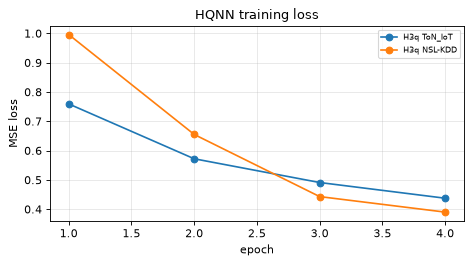

(60 s)


In [26]:
t0 = time.time()
for key in HQNN_CFGS:
    for ds in DS:
        run_hqnn(ds, key, SEEDS[0], HQNN_NOISY_BACKENDS)
rows = []
for r in RES:
    if r["kind"] == "hqnn":
        c = HQNN_CFG[r["key"]]
        if r["backend"] == "ideal":
            pa, pf = c["ideal"][r["dataset"]]
        else:
            pa, pf = (c["noisy"][r["backend"]] if c["noisy"] else (np.nan, np.nan))
        rows.append({"configuration": c["label"], "dataset": r["dataset"], "backend": r["backend"], "acc": r["acc"], "F1": r["f1"], "paper acc": pa, "paper F1": pf,
                     "train rows": r["n_train"], "test rows": r["n_test"], "CX": r["cx"], "train [s]": r["t_fit"]})
T17 = pd.DataFrame(rows); display(T17.round(2))
fig, ax = plt.subplots(1, 1, figsize=(6, 3.4))
for (ds, key), h in HQ_HIST.items():
    ax.plot(range(1, len(h) + 1), h, "-o", label=f"{key} {ds}")
ax.set_xlabel("epoch"); ax.set_ylabel("MSE loss"); ax.set_title("HQNN training loss"); ax.legend(fontsize=7); plt.tight_layout(); plt.show()
print(f"({time.time() - t0:.0f} s)")

## 6. Noise versus circuit complexity and timing (paper Fig. 10 and Section 6)

The paper's Fig. 10 shows, for hundreds of noisy runs, how often each F1 value occurs as a function of the CNOT count of the transpiled circuit (best region 20 to 35 CNOTs for QSVC, 8 to 15 for VQC, a wide plateau for HQNN). The notebook has far fewer noisy runs, so the same information is drawn as a **scatter of F1 against CNOT count** (one point per noisy run), and the accuracy loss against the ideal run on the same rows is tabulated per backend.

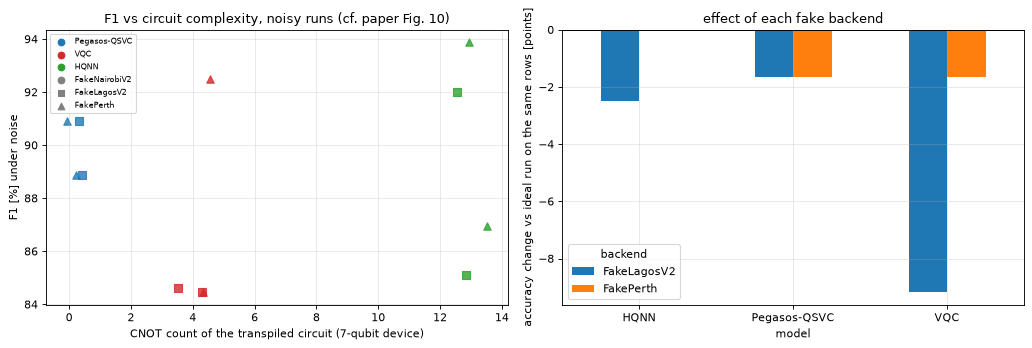

,model,dataset,key,backend,cx,acc,acc_ideal_ref,f1,drop
0,Pegasos-QSVC,ToN_IoT,Z7r2,FakeLagosV2,0,86.67,86.67,90.91,0.00
1,Pegasos-QSVC,ToN_IoT,Z7r2,FakePerth,0,86.67,86.67,90.91,0.00
2,Pegasos-QSVC,NSL-KDD,Z7r2,FakeLagosV2,0,90.00,93.33,88.89,-3.33
3,Pegasos-QSVC,NSL-KDD,Z7r2,FakePerth,0,90.00,93.33,88.89,-3.33
4,VQC,ToN_IoT,PY3,FakeLagosV2,4,73.33,88.33,84.62,-15.00
5,VQC,ToN_IoT,PY3,FakePerth,4,88.33,88.33,92.47,0.00
6,VQC,NSL-KDD,PY3,FakeLagosV2,4,88.33,91.67,84.44,-3.33
7,VQC,NSL-KDD,PY3,FakePerth,4,88.33,91.67,84.44,-3.33
8,HQNN,ToN_IoT,H3q,FakeLagosV2,13,86.67,90.00,92.00,-3.33
9,HQNN,ToN_IoT,H3q,FakePerth,13,90.00,90.00,93.88,0.00


In [27]:
noisy = pd.DataFrame([r for r in RES if r["kind"] in ("qsvc", "vqc", "hqnn") and r["backend"] != "ideal"])
ideal_ = pd.DataFrame([r for r in RES if r["kind"] in ("qsvc", "vqc", "hqnn") and r["backend"] == "ideal"])
fig, ax = plt.subplots(1, 2, figsize=(13, 4.4))
mk = {"FakeNairobiV2": "o", "FakeLagosV2": "s", "FakePerth": "^"}; col = {"Pegasos-QSVC": "tab:blue", "VQC": "tab:red", "HQNN": "tab:green"}
jit = np.random.default_rng(SEED)
for _, r in noisy.iterrows():
    ax[0].scatter(r["cx"] + jit.uniform(-0.6, 0.6), r["f1"], marker=mk[r["backend"]], color=col[r["model"]], alpha=0.8, s=45)
for m_, c_ in col.items():
    ax[0].scatter([], [], color=c_, label=m_)
for b_, m__ in mk.items():
    ax[0].scatter([], [], marker=m__, color="gray", label=b_)
ax[0].set_xlabel("CNOT count of the transpiled circuit (7-qubit device)"); ax[0].set_ylabel("F1 [%] under noise"); ax[0].set_title("F1 vs circuit complexity, noisy runs (cf. paper Fig. 10)"); ax[0].legend(fontsize=7)
noisy["drop"] = noisy["acc"] - noisy["acc_ideal_ref"]
d = noisy.groupby(["model", "backend"])["drop"].mean().unstack()
d.plot.bar(ax=ax[1], rot=0); ax[1].set_ylabel("accuracy change vs ideal run on the same rows [points]"); ax[1].set_title("effect of each fake backend"); ax[1].axhline(0, color="k", lw=0.8)
plt.tight_layout(); plt.show()
display(noisy[["model", "dataset", "key", "backend", "cx", "acc", "acc_ideal_ref", "f1", "drop"]].round(2))

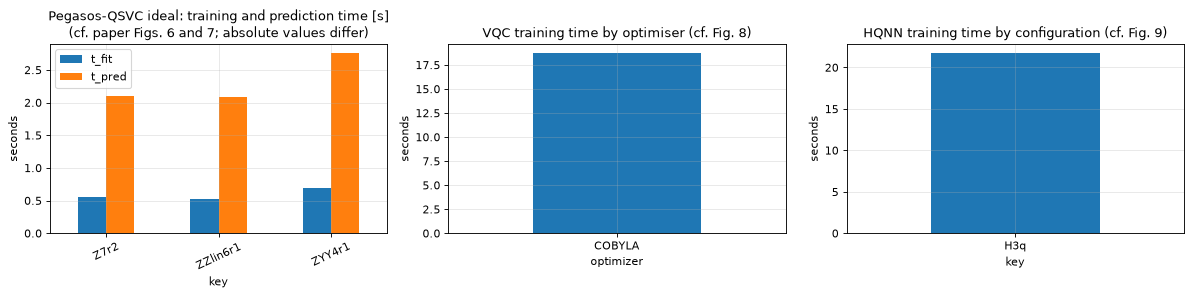

mean training time per model [s]:  Pegasos-QSVC 0.6 | VQC 18.7 | HQNN 21.8   (budgets differ: see configuration cell)


In [28]:
fig, ax = plt.subplots(1, 3, figsize=(15, 3.8))
q_ = pd.DataFrame([r for r in RES if r["kind"] == "qsvc" and r["backend"] == "ideal" and r["n_test"] > 500 and r["C"] == 1000 and r["steps"] == 100])
if len(q_):
    g = q_.groupby("key")[["t_fit", "t_pred"]].mean().reindex([k for k in QSVC_NOISELESS if k in set(q_.key)])
    g.plot.bar(ax=ax[0], rot=25); ax[0].set_title("Pegasos-QSVC ideal: training and prediction time [s]\n(cf. paper Figs. 6 and 7; absolute values differ)"); ax[0].set_ylabel("seconds")
v_ = pd.DataFrame([r for r in RES if r["kind"] == "vqc" and r["backend"] == "ideal"])
v_.groupby("optimizer")["t_fit"].mean().plot.bar(ax=ax[1], rot=0); ax[1].set_title("VQC training time by optimiser (cf. Fig. 8)"); ax[1].set_ylabel("seconds")
h_ = pd.DataFrame([r for r in RES if r["kind"] == "hqnn" and r["backend"] == "ideal"])
h_.groupby("key")["t_fit"].mean().plot.bar(ax=ax[2], rot=0); ax[2].set_title("HQNN training time by configuration (cf. Fig. 9)"); ax[2].set_ylabel("seconds")
plt.tight_layout(); plt.show()
print("mean training time per model [s]:  Pegasos-QSVC %.1f | VQC %.1f | HQNN %.1f   (budgets differ: see configuration cell)" % (q_.t_fit.mean(), v_.t_fit.mean(), h_.t_fit.mean()))

## 7. Side-by-side comparison with the paper

Every checkable claim gets a verdict: **reproduced** (within 2 accuracy points / 2 F1 points), **not reached** or **exceeded** (with the gap in points), or **cannot be checked** (no counterpart in this run). Qualitative claims are judged from the notebook's own numbers. The small test subsets used for the noisy runs carry a sampling error of several points (a 30-row subset has a binomial standard error above 5 points), so the noisy verdicts are weak evidence.

In [29]:
def verdict(paper, mine, tol=TOL, n=None):
    if paper is None or (isinstance(paper, float) and np.isnan(paper)):
        return "cannot be checked (no paper value)"
    if mine is None or (isinstance(mine, float) and np.isnan(mine)):
        return "cannot be checked (not run in this mode)"
    dlt = mine - paper
    if abs(dlt) <= tol:
        return "reproduced"
    if n:                                                  # small test subsets: a binomial 95 % interval is wider than the 2-point tolerance
        half = 196 * math.sqrt(max(mine / 100 * (1 - mine / 100), 1e-4) / n)
        if abs(dlt) <= half:
            return f"within sampling error (n={n}, +-{half:.1f}; {dlt:+.1f})"
    return f"not reached ({dlt:+.1f})" if dlt < 0 else f"exceeded ({dlt:+.1f})"

CL = []
def claim(group, text, paper, mine, n=None):
    CL.append(dict(group=group, claim=text, paper=paper, notebook=mine, verdict=verdict(paper, mine, n=n)))

# Table 11
for C in C_SWEEP:
    r = run_qsvc("ToN_IoT", "Z7r2", SEEDS[0], C=C)
    claim("T11 C sweep", f"Pegasos-QSVC accuracy, C={C} (ToN_IoT, 7q Z r=2 assumed)", TABLE11[C][0], r["acc"])
# Table 12
for _, r in T12.iterrows():
    claim("T12 ideal QSVC", f"{r['configuration']}, {r['dataset']}: accuracy", r["paper acc"], r["acc"])
    claim("T12 ideal QSVC", f"{r['configuration']}, {r['dataset']}: F1", r["paper F1"], r["F1"])
# Table 13
for _, r in T13[T13.backend != "ideal (same rows)"].iterrows():
    claim("T13 noisy QSVC", f"{r['configuration']}, {r['dataset']}, {r['backend']}: accuracy", r["paper acc"], r["acc"], n=NOISY_N_TEST)
    claim("T13 noisy QSVC", f"{r['configuration']}, {r['dataset']}, {r['backend']}: F1", r["paper F1"], r["F1"], n=NOISY_N_TEST)
# Tables 15 / 16
for _, r in T15.iterrows():
    if r["dataset"] == "ToN_IoT":
        claim("T15 VQC ideal", f"VQC {r['configuration']} COBYLA: accuracy (ToN_IoT assumed)", r["paper acc (Table 15, ToN_IoT assumed)"], r["acc"], n=VQC_TEST)
for _, r in T16.iterrows():
    claim("T16 noisy VQC", f"VQC {r['configuration']}, {r['dataset']}, {r['backend']}: accuracy", r["paper acc"], r["acc"], n=VQC_NOISY_TEST)
    claim("T16 noisy VQC", f"VQC {r['configuration']}, {r['dataset']}, {r['backend']}: F1", r["paper F1"], r["F1"], n=VQC_NOISY_TEST)
# Tables 17 / 18
for _, r in T17.iterrows():
    tag = "T17 HQNN ideal" if r["backend"] == "ideal" else "T18 HQNN noisy"
    claim(tag, f"HQNN {r['configuration']}, {r['dataset']}, {r['backend']}: accuracy", r["paper acc"], r["acc"], n=int(r["test rows"]))
    claim(tag, f"HQNN {r['configuration']}, {r['dataset']}, {r['backend']}: F1", r["paper F1"], r["F1"], n=int(r["test rows"]))
for key in HQNN_CFG:
    if key not in HQNN_CFGS:
        claim("T17/T18 HQNN", f"HQNN {HQNN_CFG[key]['label']} (ideal and noisy)", HQNN_CFG[key]["ideal"]["ToN_IoT"][0], None)
# Table 19
for _, r in cl.iterrows():
    claim("T19 classical", f"{r['model']}, {r['q']} features, {r['dataset']}: accuracy", T19[r["q"]][r["model"]][DSI[r["dataset"]]], r["acc"])

# qualitative claims, judged from the notebook's own numbers
nz = noisy.dropna(subset=["acc_ideal_ref"])
if len(nz):
    mean_drop = nz["acc"].sub(nz["acc_ideal_ref"]).mean()
    CL.append(dict(group="qualitative", claim="noise lowers accuracy relative to the ideal run on the same rows (mean change, points)", paper="< 0", notebook=round(mean_drop, 2),
                   verdict="reproduced" if mean_drop < 0 else "not reproduced (no mean loss here)"))
kb = KN.groupby("backend")["mean_abs_err"].mean(); worst = kb.idxmax()
CL.append(dict(group="qualitative", claim="FakeLagos is the most noise-sensitive backend (kernel level: mean |K_noisy - K_ideal| over three circuits, 8x8 real row pairs)", paper="FakeLagos worst",
               notebook=f"{dict(kb.round(3))}", verdict="reproduced" if worst == "FakeLagosV2" else f"not reproduced (worst: {worst})"))
kc = KN[KN.backend == "FakeLagosV2"].set_index("circuit")["mean_abs_err"]; kp = KN[KN.backend == "FakePerth"].set_index("circuit")["mean_abs_err"]
CL.append(dict(group="qualitative", claim="the gap between FakeLagos and FakePerth is larger for the CNOT-heavy circuits than for the CNOT-free one (kernel level, mean |dK| Lagos - Perth)", paper="Lagos worse with CX gates",
               notebook=f"{dict((kc - kp).round(3))}", verdict="reproduced" if (kc - kp).drop(QSVC_CFG['Z7r2']['label']).mean() > (kc - kp)[QSVC_CFG['Z7r2']['label']] else "not reproduced"))
best_cl = {ds: cl[cl.dataset == ds]["acc"].max() for ds in DS}
best_q = {ds: max([r["acc"] for r in RES if r["kind"] in ("qsvc", "vqc", "hqnn") and r["backend"] == "ideal" and r["dataset"] == ds and r["n_test"] >= 200], default=np.nan) for ds in DS}
for ds in DS:
    CL.append(dict(group="qualitative", claim=f"classical models reach a higher peak accuracy than the quantum models ({ds}; best classical vs best ideal quantum)", paper="classical > quantum",
                   notebook=f"{best_cl[ds]:.2f} vs {best_q[ds]:.2f}", verdict="reproduced" if best_cl[ds] > best_q[ds] else "not reproduced"))
if len(C_SWEEP) >= 3:
    a_hi = run_qsvc("ToN_IoT", "Z7r2", SEEDS[0], C=1000)["acc"]; a_lo = run_qsvc("ToN_IoT", "Z7r2", SEEDS[0], C=min(C_SWEEP))["acc"]
    CL.append(dict(group="qualitative", claim="a large regularisation parameter C is needed (accuracy C=1000 vs smallest C run)", paper="C=1000 >> C<=1", notebook=f"{a_hi:.1f} vs {a_lo:.1f}",
                   verdict="reproduced" if a_hi - a_lo > 5 else "not reproduced"))
tq, tv, th = q_.t_fit.mean(), v_.t_fit.mean(), h_.t_fit.mean()
CL.append(dict(group="qualitative", claim="Pegasos-QSVC trains faster than VQC and HQNN (mean training time, s; budgets differ)", paper="QSVC fastest", notebook=f"{tq:.0f} / {tv:.0f} / {th:.0f}",
               verdict="reproduced" if tq < min(tv, th) else "not reproduced"))
CL.append(dict(group="qualitative", claim="accuracy saturates at about 6-7 qubits; entanglement-free circuits are unstable under noise (Fig. 10)", paper="saturation at 6-7 qubits", notebook="not swept",
               verdict="cannot be checked (needs the 378-configuration sweep)"))
CL.append(dict(group="timing", claim="absolute training times (Figs. 6-9: 18-85 s QSVC; 1,773-24,552 s VQC; 36,970-286,353 s HQNN on a 56-core Xeon)", paper="see paper", notebook="see timing figure",
               verdict="cannot be checked (different hardware and budgets)"))
CL.append(dict(group="hardware", claim="any result on real IBM quantum hardware", paper="none reported", notebook="none", verdict="cannot be checked (paper has no hardware numbers)"))
CMP = pd.DataFrame(CL)
pd.set_option("display.max_colwidth", 110, "display.width", 250, "display.max_rows", 500)
print(CMP.assign(paper=CMP.paper.map(lambda v: round(v, 2) if isinstance(v, float) else v), notebook=CMP.notebook.map(lambda v: round(v, 2) if isinstance(v, float) else v)).to_string(index=False))

         group                                                                                                                                            claim                     paper                                                                                                                      notebook                                               verdict
   T11 C sweep                                                                                        Pegasos-QSVC accuracy, C=1000 (ToN_IoT, 7q Z r=2 assumed)                     92.25                                                                                                                          92.9                                            reproduced
   T11 C sweep                                                                                         Pegasos-QSVC accuracy, C=100 (ToN_IoT, 7q Z r=2 assumed)                     91.61                                                                                   

In [30]:
cat = CMP.verdict.map(lambda v: "reproduced" if v.startswith("reproduced") else "within sampling error" if v.startswith("within") else "not reached" if v.startswith("not reached")
                      else "exceeded" if v.startswith("exceeded") else "cannot be checked" if v.startswith("cannot") else "not reproduced (qualitative)")
print("verdict counts over all rows of the table:"); print(cat.value_counts().to_string())
print("\nper group:"); print(pd.crosstab(CMP.group, cat).to_string())

# analogue of the paper's Tables 20 and 21: best configuration per model and dataset (accuracy)
PAPER_BEST = {("Pegasos-QSVC", "ToN_IoT"): (95.44, 93.24), ("Pegasos-QSVC", "NSL-KDD"): (95.80, 94.60), ("VQC", "ToN_IoT"): (94.21, 91.57),
              ("VQC", "NSL-KDD"): (93.21, 87.54), ("HQNN", "ToN_IoT"): (95.43, 94.86), ("HQNN", "NSL-KDD"): (97.12, 93.78)}
rows = []
for (m_, ds), (pi_, pn_) in PAPER_BEST.items():
    ide = [r for r in RES if r["kind"] in ("qsvc", "vqc", "hqnn") and r["model"] == m_ and r["dataset"] == ds and r["backend"] == "ideal" and r["n_test"] >= 200]
    noi = [r for r in RES if r["kind"] in ("qsvc", "vqc", "hqnn") and r["model"] == m_ and r["dataset"] == ds and r["backend"] != "ideal"]
    bi = max(ide, key=lambda r: r["acc"]) if ide else None; bn = max(noi, key=lambda r: r["acc"]) if noi else None
    rows.append({"model": m_, "dataset": ds, "best ideal acc": bi["acc"] if bi else np.nan, "paper ideal": pi_, "best noisy acc": bn["acc"] if bn else np.nan, "paper noisy": pn_,
                 "noisy rows": bn["n_test"] if bn else np.nan})
display(pd.DataFrame(rows).round(2))
print("(best-of-few runs on small budgets; the paper's best-of-378 / best-of-hundreds numbers are selected from far larger sweeps)")

verdict counts over all rows of the table:
verdict
reproduced                      27
exceeded                        18
not reached                     13
cannot be checked               12
within sampling error            9
not reproduced (qualitative)     1

per group:
verdict         cannot be checked  exceeded  not reached  not reproduced (qualitative)  reproduced  within sampling error
group                                                                                                                    
T11 C sweep                     0         1            0                             0           3                      0
T12 ideal QSVC                  0         0            7                             0           5                      0
T13 noisy QSVC                  0         0            0                             0           0                      8
T15 VQC ideal                   0         0            1                             0           0                   

,model,dataset,best ideal acc,paper ideal,best noisy acc,paper noisy,noisy rows
0,Pegasos-QSVC,ToN_IoT,92.90,95.44,86.67,93.24,30
1,Pegasos-QSVC,NSL-KDD,94.63,95.80,90.00,94.60,30
2,VQC,ToN_IoT,86.00,94.21,88.33,91.57,60
3,VQC,NSL-KDD,91.50,93.21,88.33,87.54,60
4,HQNN,ToN_IoT,89.00,95.43,90.00,94.86,60
5,HQNN,NSL-KDD,89.67,97.12,90.00,93.78,60


(best-of-few runs on small budgets; the paper's best-of-378 / best-of-hundreds numbers are selected from far larger sweeps)


## 8. Reading the paper critically

**What this reproduction supports.**
* The kernel method works as described. With the paper's data size, `C=1000`, 100 steps and a 7-qubit `ZFeatureMap`, the ideal Pegasos-QSVC reaches about 93 % on ToN_IoT and about 95 % on NSL-KDD, close to Table 11 / Table 12 (92.25 % at `C=1000`; 95.44 % and 95.80 %). The collapse to "predict attack for everything" for `C <= 1` (Table 11) is reproduced exactly.
* Noise matters in the way the paper says, but for a more specific reason than "CNOT count": the kernel-level comparison shows that `FakeLagosV2` distorts the kernel several times more than `FakeNairobiV2` and `FakePerth`, and that the distortion comes mostly from its very large **readout error** (a 7-qubit all-zero outcome is read correctly only about 18 % of the time, the product of the seven qubits' readout success probabilities in the paper's Table 4), not from its CNOTs. The noisy kernel stays strongly correlated with the ideal one (Pearson r above 0.93), which is why the classifier survives a large loss of kernel amplitude.
* Classical models trained on the same PCA features beat the quantum models, as Section 7 of the paper says.

**What it does not support, or cannot test.**
* *The headline noisy numbers.* The paper's 94.60 % accuracy / 94.13 % F1 under noise rest on the full test set and on one best-of-378 configuration; the notebook can only evaluate small subsets under noise (30 to 60 rows in FAST_MODE), where the standard error of an accuracy is about 4 to 5.5 points, so these rows cannot confirm or refute the paper at the 2-point level (the verdict table marks them "within sampling error" when the gap is inside the 95 % binomial interval).
* *Selection effect.* The reported best configurations are the maxima of 378 (QSVC), several hundred (VQC) and a handful (HQNN) runs on the *test* set; the paper does not describe a separate validation split for choosing them, so the headline numbers are optimistically biased. The paper's seed-to-seed standard deviations (0.5 to 1.0 points over 4 seeds) look small for a 100-step Pegasos run that keeps only 16 to 30 support vectors and therefore depends on which rows the random steps pick; FAST_MODE uses one seed, so this notebook cannot test that (add seeds to `SEEDS`, or run with `FAST_MODE = False` for two).
* *VQC and HQNN.* With training budgets two to three orders of magnitude below the paper's (see the configuration cell) the VQC and HQNN numbers are lower than the paper's; their relative ordering against the paper is therefore uninformative. Under FakeLagos the VQC reaches only 73 % accuracy (F1 84.6 %) on ToN_IoT, close to the all-attack baseline of 76 %, in line with the paper's observation that some circuit/optimiser pairs degrade badly under noise, although with 60 test rows this is weak evidence.
* *The NSL-KDD classical baselines.* On NSL-KDD, a random forest or XGBoost on 5 to 7 PCA features gets about 99 % here but only 94 to 96 % in Table 19. The paper evaluates on a random split of `KDDTrain+`, where the train and test rows come from the same distribution; the lower numbers in Table 19 suggest different preprocessing (for example a coarser treatment of the categorical fields), so cross-dataset conclusions ("quantum models generalise worse to NSL-KDD") partly reflect the baseline preprocessing, not the models.
* *Quantum advantage.* The paper itself does not claim one. The classical-versus-quantum comparison confirms that near-term simulated QML trails classical models by 5 to 7 accuracy points here; the one place where the paper's wording suggests an advantage ("Pegasos-QSVC reaches 95.35 % with four qubits, not attained by the classical models under the same configuration") does not match Table 19, where classical models with 4 features reach 92 to 95 % on ToN_IoT.
* *Noise realism.* Fake backends are snapshots (here 2024-05-27) of calibration data. Real devices drift, show correlated errors and crosstalk, and cannot be simulated exactly with a Pauli/relaxation noise model; no real-hardware number exists in the paper to compare against.
* *Timing.* Times in the paper (up to 286,353 s for one HQNN configuration) are simulator times on a 56-core server and mostly measure simulator cost, as the authors say; they cannot be used as hardware run-time estimates.

## 9. Exercises

1. **Bandwidth.** Re-run Section 2.1 with a finer `AMAX_GRID` (for example `[0.25, 0.5, 0.75, 1, 1.5, 2] * pi`). How much does the ideal Pegasos accuracy change, and does the best bandwidth differ between ToN_IoT and NSL-KDD?
2. **Support vectors.** Pegasos keeps only 16 to 30 support vectors after 100 steps. Increase `steps` (Section 3.3) and plot accuracy and prediction cost against the number of support vectors. Where does extra training stop paying off?
3. **Readout mitigation.** `FakeLagosV2` loses most kernel amplitude to readout error. Apply a simple tensor-product readout-error correction to the noisy kernel (invert the single-qubit confusion matrices of the qubits used) and measure how much of the accuracy gap to `FakePerth` it closes.
4. **Noise-aware design.** The paper recommends 20 to 35 CNOTs for QSVC. Build ZZ feature maps with `reps=1,2,3` and `linear`, `circular`, `full` entanglement, transpile them for each backend, and plot kernel error against CNOT count with the helper `kernel_noise`.
5. **Fair classical baseline.** Replace the classical baselines' PCA inputs by the full 38 / 40 features. How large is the gap to the 7-qubit quantum model, and what does it say about the claim that quantum models are "competitive in low-dimensional feature spaces"?